# From Forecasts to Decisions: Inventory Planning with NumPyro and JAX

A probabilistic forecast gives us a distribution over future demand. The order we place for the next quarter is a single vector of numbers. To go from one to the other we need a loss function and a choice of **which functional** of the loss distribution we minimize: its mean, a quantile or its tail average. This notebook makes that choice concrete on a small multi-period inventory problem, and shows how much the choice matters when the forecast stays the same.

We generate weekly demand from a known generative model with a drifting level, yearly seasonality and price promotions. We fit a Bayesian forecasting model with [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/) and turn the posterior predictive draws into a scenario matrix. We then compute four order plans from the same scenarios: a plan against the mean forecast, a chance-constrained plan, an expected cost plan and a CVaR plan.

We solve the last two with a projected gradient method written in JAX (`jax.lax.scan` inside `jax.jit`, and `jax.vmap` over the risk weight to trace the frontier), and we cross-check the solutions against a linear program solved with [cvxpy](https://www.cvxpy.org/). The inspiration is the [stochastic energy planning example](https://github.com/fico-xpress/xpress-community/tree/main/StochasticEnergyPlanning) in the FICO Xpress community repository, which combines a PyMC forecast with chance-constrained and CVaR optimization in Xpress.

The notebook assumes that you have written a NumPyro model before and that you know what a convex optimization problem is. It does not assume any background in stochastic programming.

Here is the outline:

1. **Prepare Notebook.** Magics, imports and plotting defaults.
2. **The Decision Problem.** The inventory dynamics, the loss and the four plans.
3. **Generate Data.** Weekly demand and a promotion calendar from a NumPyro generative model.
4. **Forecasting Model.** A local level plus Fourier seasonality plus price model with a negative binomial likelihood.
5. **Model Fitting.** NUTS, diagnostics and parameter recovery.
6. **Demand Scenarios.** Joint posterior predictive draws over the horizon.
7. **Inventory Simulator.** The loss function as a `jax.lax.scan`, vectorized over scenarios.
8. **Decision Plans.** The four plans and the JAX solver.
9. **Out of Sample Evaluation.** Cost and service level on held-out scenarios.
10. **Pareto Frontier.** The price of tail risk reduction.
11. **Convex Solver Cross Check.** The same problems as a linear program in cvxpy.
12. **Conclusion.** What we learned.

## Prepare Notebook

The `jaxtyping` magic below wraps every function defined in this notebook with a run-time type checker (`beartype`). Inside compiled code the check runs once, when the function is traced, so it costs nothing afterwards.

In [1]:
%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

Next, we import the libraries and set the plotting defaults.

In [2]:
import warnings
from typing import NamedTuple

import arviz as az
import cvxpy as cp
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import xarray as xr
from jax import random
from jaxtyping import Array, Float, Int, PRNGKeyArray, ScalarLike
from numpyro import handlers
from numpyro.distributions import Distribution
from numpyro.infer import MCMC, NUTS, Predictive
from numpyro.infer.reparam import LocScaleReparam
from numpyro_forecast import Horizon, innovations, predict, to_datatree
from numpyro_forecast.features import fourier_features

numpyro.set_host_device_count(4)

seed: int = 42
rng_key: PRNGKeyArray = random.PRNGKey(seed)

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

## The Decision Problem

We plan the orders of one product for the next quarter. Let $H$ be the number of weeks in the planning horizon and let $D_t$ be the demand in week $t = 1, \dots, H$. At the start of week $t$ we receive $x_t \geq 0$ units that we ordered in advance. We start the quarter with $I_0$ units on hand. The inventory position $I_t$ at the end of week $t$ follows the recursion

$$
I_t = I_{t-1} + x_t - D_t.
$$

A negative $I_t$ is a backlog: demand that we could not serve in week $t$ and that we carry into the next week.

Each week we pay a holding cost $h$ for every unit on the shelf and a backorder cost $p$ for every unit in backlog. To write these costs we need the positive part and the negative part of a number $a$:

$$
(a)^{+} = \max(a, 0), \qquad (a)^{-} = \max(-a, 0).
$$

The loss of the plan $x = (x_1, \dots, x_H)$ against the demand path $D = (D_1, \dots, D_H)$ is the sum of both costs over the quarter:

$$
L(x, D) = \sum_{t=1}^{H} \left[ h \, (I_t)^{+} + p \, (I_t)^{-} \right].
$$

There is no purchase cost in $L$. Every unit of demand is bought once, either on time or as a backlog that we serve later, and leftover units carry into the next quarter. The purchase cost is therefore the same for every plan and does not change the decision. The plan controls the *timing* of the orders. If we order too early we pay holding costs, and if we order too late we pay backorder costs.

The forecasting model gives us the posterior predictive distribution of the demand path $D$. We represent it by $S$ joint draws $D^{(1)}, \dots, D^{(S)}$, one path of $H$ weeks each, which we call scenarios. The decision $x$ must be fixed before we observe any demand, so one plan has to hold up across all of these scenarios. We approximate the expected loss of a plan by its sample average over the scenarios:

$$
\text{E}[L(x, D)] \approx \frac{1}{S} \sum_{s=1}^{S} L(x, D^{(s)}).
$$

Because the dynamics are linear, it is useful to work with cumulative quantities. Let $X_t = \sum_{\tau \leq t} x_\tau$ be the cumulative orders and $C_t = \sum_{\tau \leq t} D_\tau$ the cumulative demand up to week $t$. Unrolling the recursion gives

$$
I_t = I_0 + X_t - C_t.
$$

We compare four ways of turning the scenarios into a plan.

### Mean Forecast Plan

We replace the distribution by the mean path of the scenarios, $\bar{D} = \frac{1}{S} \sum_{s} D^{(s)}$, and solve the deterministic problem

$$
\min_{x \geq 0} \; L(x, \bar{D}).
$$

This is what a point forecast gives you. Against a single path, the cheapest plan keeps the inventory at zero, so the cumulative orders follow the cumulative mean demand.

### Chance-Constrained Plan

We ask for a service level instead of a cost. Let $\alpha$ be the stockout probability we accept in any given week. The constraint is

$$
\text{P}(I_t \geq 0) \geq 1 - \alpha \quad \text{for every } t = 1, \dots, H,
$$

and we take the cheapest plan that satisfies it. The constraint is per week. The probability of at least one stockout in the quarter is larger, and we report both below. Let $Q_{1-\alpha}(C_t)$ be the $(1 - \alpha)$ quantile of the cumulative demand $C_t$ across the scenarios. With $I_t = I_0 + X_t - C_t$ the constraint becomes

$$
X_t \geq Q_{1-\alpha}(C_t) - I_0.
$$

The uncertainty collapses into a quantile path and no optimizer is needed. Note that the constraint counts how often we run out and ignores by how much.

### Expected Cost Plan

We minimize the sample average of the loss,

$$
\min_{x \geq 0} \; \frac{1}{S} \sum_{s=1}^{S} L(x, D^{(s)}),
$$

which is the sample average approximation of the Bayes decision. Here is an important observation. In cumulative orders the expected loss separates by week, and each week is a newsvendor problem. The plan that minimizes the expected loss therefore orders up to the $p / (p + h)$ quantile of cumulative demand in every week, the newsvendor critical fractile.

The constraint $x \geq 0$ means that $X_t$ is non-decreasing. Cumulative demand is non-decreasing in every scenario, so its quantile path is non-decreasing too, and the constraint does not bind.

With the costs we use below the fractile is $0.909$, so this plan accepts a stockout in about $9\%$ of the weeks. The service level is a consequence of the costs, and the plan has no service target of its own.

The same fractile explains why the smallest feasible chance-constrained plan is also the cheapest one. A service level of $1 - \alpha = 0.95$ is above the fractile, so ordering more than the quantile path adds more expected holding cost than it saves in backorder cost.

### CVaR Plan

We put a price on the tail. Let $\text{VaR}_\alpha(L) = Q_{1-\alpha}(L)$ be the $(1 - \alpha)$ quantile of the loss, the value at risk. The conditional value at risk is the expected loss beyond that quantile:

$$
\text{CVaR}_\alpha(L) = \text{E}\left[ L \mid L \geq \text{VaR}_\alpha(L) \right].
$$

Let $L_{(1)} \geq L_{(2)} \geq \dots \geq L_{(S)}$ be the losses of the $S$ scenarios sorted from largest to smallest, and let $k = \alpha S$ be an integer. The sample estimate of the conditional value at risk is the mean of the $k$ largest losses:

$$
\widehat{\text{CVaR}}_\alpha(L) = \frac{1}{k} \sum_{i=1}^{k} L_{(i)}.
$$

This equals the definition above as long as no two losses tie at the quantile, which we do not expect with real-valued losses. We use the same $\alpha = 0.05$ for the CVaR tail and for the chance constraint. We minimize

$$
\min_{x \geq 0} \; \text{E}[L(x, D)] + \lambda \, \text{CVaR}_\alpha(L(x, D)),
$$

where $\lambda \geq 0$ is the weight we put on the worst $\alpha$ fraction of the quarters. With $\lambda = 0$ we recover the expected cost plan. The CVaR term counts how bad the worst quarters are.

All plans use the same scenarios. The differences we see below come from the functional alone.

Let's fix the length of the history, the horizon, the seasonal period, the promotion settings, the costs and the initial stock. The `Problem` tuple travels through every function below, so changing the costs is a one-line edit.

In [3]:
T_OBS = 156  # three years of weekly history
HORIZON = 13  # one quarter ahead
PERIOD = 52.0  # yearly seasonality in weeks
DISCOUNT = 0.3  # price cut in a promotion week
PROMO_PROB = 0.1  # chance that a given week is a promotion week
DURATION = T_OBS + HORIZON


class Problem(NamedTuple):
    """Costs and initial state of the inventory problem."""

    holding_cost: float
    backorder_cost: float
    initial_inventory: float
    alpha: float


problem = Problem(
    holding_cost=0.3, backorder_cost=3.0, initial_inventory=300.0, alpha=0.05
)
critical_fractile = problem.backorder_cost / (
    problem.backorder_cost + problem.holding_cost
)
print(f"critical fractile p / (p + h) = {critical_fractile:.3f}")

critical fractile p / (p + h) = 0.909


## Generate Data

We simulate weekly demand from a generative model with a slowly drifting level, yearly seasonality, price promotions and negative binomial noise. We write the model in NumPyro, fix the true parameters with the `do` handler and take one draw with `Predictive`. This is the NumPyro counterpart of `pm.do` followed by `pm.sample_prior_predictive(draws=1)`.

Why price? A covariate helps the forecast only if we know its future values. Price qualifies because the retailer sets it, so the promotion calendar for the next quarter is part of the plan. Weather or competitor actions would need a forecast of their own.

We model a promotion as a $30\%$ cut from the list price, and we enter the price as the log of the price relative to the list price. The coefficient on that covariate is then the price `elasticity`, and a discount of $30\%$ with an elasticity of $-1.5$ lifts demand by a factor of $0.7^{-1.5} \approx 1.71$.

First, let's build the Fourier design matrix over the full duration (history plus horizon) and define the generator. The promotion weeks are a Bernoulli draw per week under the `time` plate. We draw this calendar once and then treat it as the retailer's plan, which is known over the horizon. The `log_price` site is deterministic so that we can read the price path back from the draw.

In [4]:
fourier = fourier_features(DURATION, period=PERIOD, num_terms=2)


def demand_generator(fourier: Float[Array, "duration features"]) -> None:
    """Weekly demand with a drifting level, yearly seasonality and price promotions."""
    duration, num_features = fourier.shape
    intercept = numpyro.sample("intercept", dist.Normal(6.0, 1.0))
    beta = numpyro.sample(
        "beta", dist.Normal(0.0, 0.3).expand([num_features]).to_event(1)
    )
    elasticity = numpyro.sample("elasticity", dist.Normal(0.0, 1.0))
    drift_scale = numpyro.sample("drift_scale", dist.HalfNormal(0.05))
    concentration = numpyro.sample("concentration", dist.Gamma(20.0, 1.0))

    with numpyro.plate("time", duration):
        promo = numpyro.sample("promo", dist.Bernoulli(PROMO_PROB))
        drift = numpyro.sample("drift", dist.Normal(0.0, drift_scale))

    log_price = numpyro.deterministic("log_price", promo * jnp.log(1.0 - DISCOUNT))
    level = jnp.cumsum(drift)
    log_rate = intercept + level + fourier @ beta + elasticity * log_price
    numpyro.sample("y", dist.NegativeBinomial2(jnp.exp(log_rate), concentration))


true_params = {
    "intercept": jnp.log(400.0),
    "beta": jnp.array([0.25, 0.10, -0.05, 0.08]),
    "elasticity": jnp.array(-1.5),
    "drift_scale": jnp.array(0.015),
    "concentration": jnp.array(30.0),
}

Next, we take one draw from the intervened model. We keep the demand, the price path and the promotion weeks, and we split the demand into the observed history and the true future. The covariate matrix of the forecasting model is the Fourier design plus the log relative price as a last column.

In [5]:
rng_key, key_data = random.split(rng_key)
generator = Predictive(handlers.do(demand_generator, data=true_params), num_samples=1)
draw = generator(key_data, fourier)

demand_full = draw["y"][0]
log_price = draw["log_price"][0]
promo_weeks = np.flatnonzero(np.asarray(draw["promo"][0]))
covariates = jnp.concatenate([fourier, log_price[:, None]], axis=1)

# time at axis -2, one observation dim at -1
data = demand_full[:T_OBS, None].astype(jnp.int32)
demand_future_true = demand_full[T_OBS:].astype(jnp.float32)
weeks = np.arange(DURATION)
promo_weeks_future = promo_weeks[promo_weeks >= T_OBS]
print(f"data shape {data.shape}, covariates shape {covariates.shape}")
print(f"{promo_weeks.size} promotion weeks, {promo_weeks_future.size} in the horizon")
print(f"promotion weeks in the horizon: {promo_weeks_future}")

data shape (156, 1), covariates shape (169, 5)
22 promotion weeks, 2 in the horizon
promotion weeks in the horizon: [164 167]


Let's look at the demand series and the price path below it. The dashed line marks the start of the planning horizon.

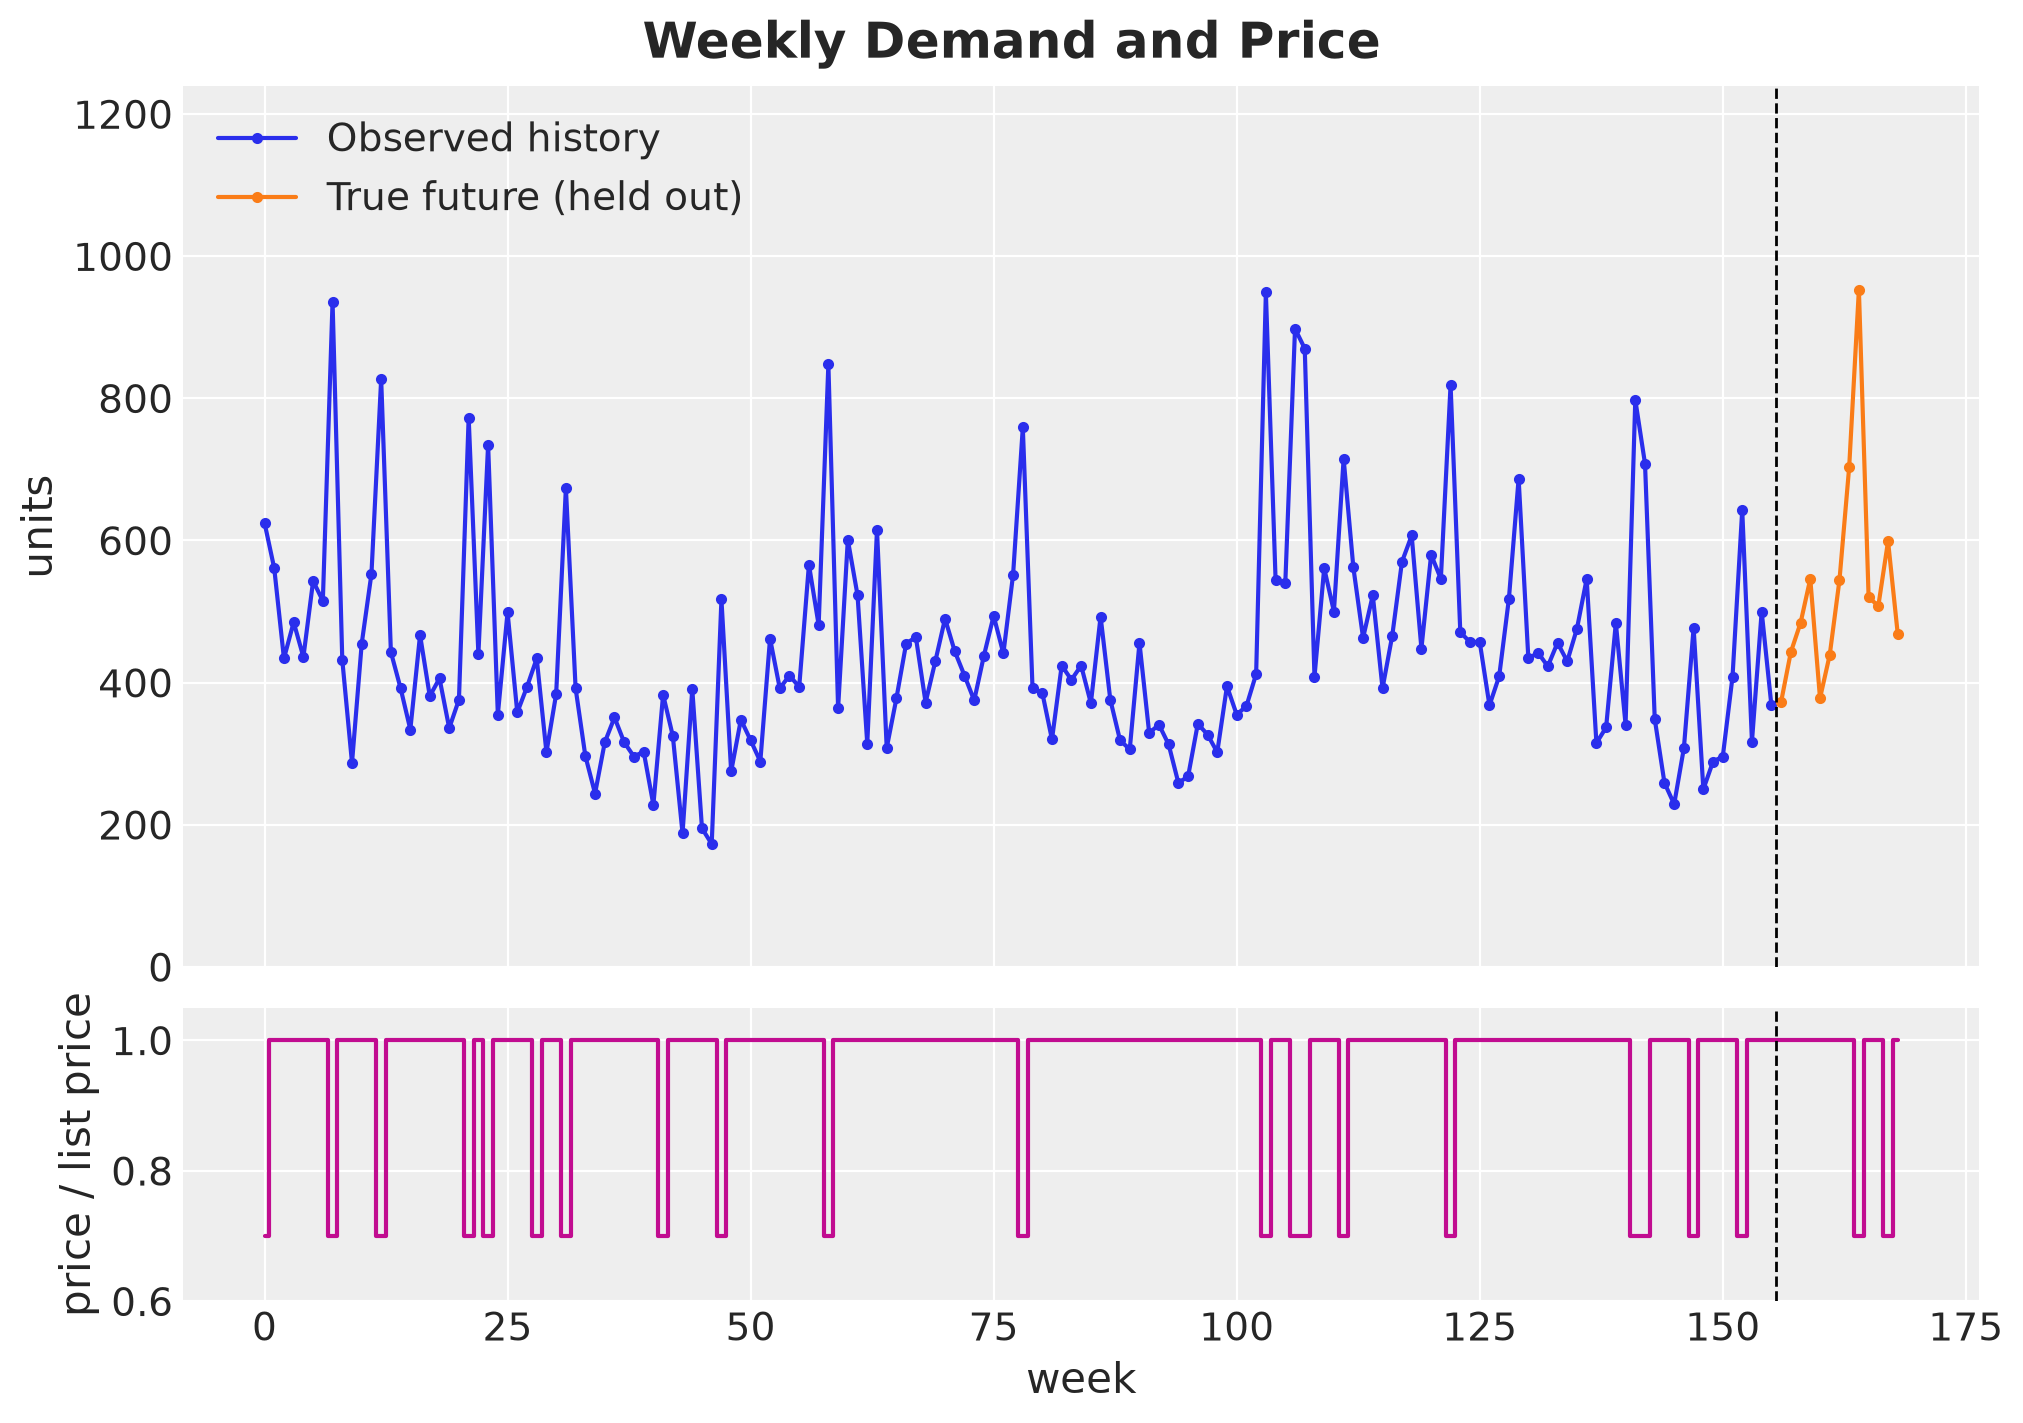

In [6]:
fig, axes = plt.subplots(
    nrows=2, figsize=(10, 7), sharex=True, height_ratios=[3, 1], layout="constrained"
)
ax = axes[0]
ax.plot(
    weeks[:T_OBS],
    np.asarray(data[:, 0]),
    "o-",
    markersize=3,
    color="C0",
    label="Observed history",
)
ax.plot(
    weeks[T_OBS:],
    np.asarray(demand_future_true),
    "o-",
    markersize=3,
    color="C1",
    label="True future (held out)",
)
ax.axvline(T_OBS - 0.5, color="black", linestyle="--", linewidth=1)
ax.legend(loc="upper left")
ax.set(ylabel="units", ylim=(0, 1.3 * float(demand_full.max())))
ax = axes[1]
ax.step(
    weeks,
    np.exp(np.asarray(log_price)),
    where="mid",
    color="C3",
)
ax.axvline(T_OBS - 0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="week", ylabel="price / list price", ylim=(0.6, 1.05))
fig.suptitle("Weekly Demand and Price", fontsize=18, fontweight="bold");

We see a yearly cycle on top of a level that stays within about $\pm 10\%$ of its start over the three years, and a spike in every promotion week. The spikes are the part of the series that the price covariate explains. The true future appears in the plots as a reference, and we score the plans on it at the very end.

## Forecasting Model

The forecasting model has the same structure as the generator, so it is well specified. We write it as a `numpyro_forecast` model: a plain function `(covariates, data=None)` whose first line derives the train/forecast split from the array shapes.

- **Horizon.** `Horizon.from_data` reads the observed length from `data` and the full duration from `covariates`. The horizon is whatever the covariates have beyond the data.
- **Innovations.** `innovations` samples the level increments under a `time` plate over the history and under a separate `time_future` plate over the horizon, so one model both trains and forecasts.
- **Prediction.** `predict` with a link function registers `obs` over the training window and `forecast` over the horizon, here with a negative binomial likelihood on the log rate.

Let's define the model. The last column of `covariates` is the log relative price. The prior on `elasticity` is centered at zero, so the data determine its sign and size.

In [7]:
def demand_model(
    covariates: Float[Array, "duration features"],
    data: Int[Array, "t_obs 1"] | None = None,
) -> None:
    """Local level plus seasonality plus price, negative binomial likelihood."""
    h = Horizon.from_data(covariates, data)
    fourier, log_price = covariates[..., :-1], covariates[..., -1]
    num_features = fourier.shape[-1]
    intercept = numpyro.sample("intercept", dist.Normal(6.0, 1.0))
    beta = numpyro.sample(
        "beta", dist.Normal(0.0, 0.3).expand([num_features]).to_event(1)
    )
    elasticity = numpyro.sample("elasticity", dist.Normal(0.0, 1.0))
    drift_scale = numpyro.sample("drift_scale", dist.HalfNormal(0.05))
    concentration = numpyro.sample("concentration", dist.Gamma(20.0, 1.0))
    drift = innovations(
        h, "drift", dist.Normal(0.0, drift_scale), reparam=LocScaleReparam(0)
    )
    level = jnp.cumsum(drift, axis=-2)
    regression = (fourier @ beta + elasticity * log_price)[..., None]
    log_rate = intercept + level + regression

    def likelihood(eta: Float[Array, "..."]) -> Distribution:
        return dist.NegativeBinomial2(jnp.exp(eta), concentration)

    predict(h, likelihood, log_rate)

## Model Fitting

We fit the model with NUTS, four chains of $1{,}000$ draws each. Every draw is one joint scenario later on, so we keep all $4{,}000$ of them.

In [8]:
rng_key, key_fit = random.split(rng_key)
mcmc = MCMC(
    NUTS(demand_model, target_accept_prob=0.9),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
    chain_method="parallel",
    progress_bar=False,
)
mcmc.run(key_fit, covariates[:T_OBS], data)
posterior = mcmc.get_samples()

`to_datatree` turns the posterior into an `xarray.DataTree` in the ArviZ schema. Because `covariates` extends beyond `data`, the tree also carries in-sample posterior predictive draws and the forecast draws over the horizon.

In [9]:
rng_key, key_tree = random.split(rng_key)
idata = to_datatree(key_tree, demand_model, posterior, data, covariates, num_chains=4)
idata

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:  numpyro
│       creation_library:   numpyro_forecast
│       sample_dims:        ['chain', 'draw']
├── Group: /posterior
│       Dimensions:                 (chain: 4, draw: 1000, beta_dim_0: 4,
│                                    drift_dim_0: 156, drift_dim_1: 1,
│                                    drift_decentered_dim_0: 156,
│                                    drift_decentered_dim_1: 1)
│       Coordinates:
│         * chain                   (chain) int64 32B 0 1 2 3
│         * draw                    (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│         * beta_dim_0              (beta_dim_0) int64 32B 0 1 2 3
│         * drift_dim_0             (drift_dim_0) int64 1kB 0 1 2 3 ... 152 153 154 155
│         * drift_dim_1             (drift_dim_1) int64 8B 0
│         * drift_decentered_dim_0  (drift_decentered_dim_0) int64 1kB 0 1 2 ... 154 155
│         * drift_decentered_dim_1  (drift_decentered_dim_1) int64 8B 0
│       Data variables:
│           beta                    (chain, draw, beta_dim_0) float32 64kB 0.2101 ......
│           concentration           (chain, draw) float32 16kB 29.4 28.92 ... 34.97
│           drift                   (chain, draw, drift_dim_0, drift_dim_1) float32 2MB ...
│           drift_decentered        (chain, draw, drift_decentered_dim_0, drift_decentered_dim_1) float32 2MB ...
│           drift_scale             (chain, draw) float32 16kB 0.01975 ... 0.01831
│           elasticity              (chain, draw) float32 16kB -1.93 -1.857 ... -1.484
│           intercept               (chain, draw) float32 16kB 5.967 5.869 ... 5.896
│       Attributes:
│           created_at:                 2026-10-17T21:34:20.399089+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /posterior_predictive
│       Dimensions:  (chain: 4, draw: 1000, time: 156, obs_dim: 1)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) int64 1kB 0 1 2 3 4 5 6 7 ... 149 150 151 152 153 154 155
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (chain, draw, time, obs_dim) int32 2MB 777 478 480 ... 233 419 482
│       Attributes:
│           created_at:                 2026-10-17T21:34:20.899660+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:  (time: 156, obs_dim: 1)
│       Coordinates:
│         * time     (time) int64 1kB 0 1 2 3 4 5 6 7 ... 149 150 151 152 153 154 155
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (time, obs_dim) int32 624B 625 561 434 485 436 ... 643 317 500 368
│       Attributes:
│           created_at:                 2026-10-17T21:34:20.899906+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                []
├── Group: /constant_data
│       Dimensions:        (time: 156, covariate_dim: 5)
│       Coordinates:
│         * time           (time) int64 1kB 0 1 2 3 4 5 6 ... 150 151 152 153 154 155
│         * covariate_dim  (covariate_dim) int64 40B 0 1 2 3 4
│       Data variables:
│           covariates     (time, covariate_dim) float32 3kB 0.0 0.0 1.0 ... 0.9709 -0.0
│       Attributes:
│           created_at:                 2026-10-17T21:34:20.900097+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                []
├── 

The tree holds the posterior, the in-sample posterior predictive, the observed data and the forecast draws as separate groups, so every ArviZ function works on it directly. Let's check the sampler diagnostics for the global parameters.

In [10]:
global_params = ["intercept", "beta", "elasticity", "drift_scale", "concentration"]
az.summary(idata, var_names=global_params)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,5.949,0.061,5.8,6.1,3151,2834,1.00,0.0011,0.00098
beta[0],0.213,0.0273,0.16,0.26,3848,2962,1.00,0.00044,0.00041
beta[1],0.1003,0.0237,0.052,0.14,4938,2802,1.00,0.00034,0.0004
beta[2],-0.0262,0.0275,-0.076,0.027,3976,2745,1.00,0.00044,0.00048
beta[3],0.0687,0.0222,0.027,0.11,4620,3094,1.00,0.00033,0.00034
elasticity,-1.591,0.131,-1.8,-1.3,5908,2878,1.00,0.0017,0.0022
drift_scale,0.0167,0.0068,0.0052,0.029,1878,2145,1.00,0.00016,0.00015
concentration,30.6,3.4,25,37,5702,3161,1.00,0.046,0.057


The $\hat{R}$ values are at $1.0$ and the effective sample sizes are in the thousands, which is good! Let's also look at the traces.

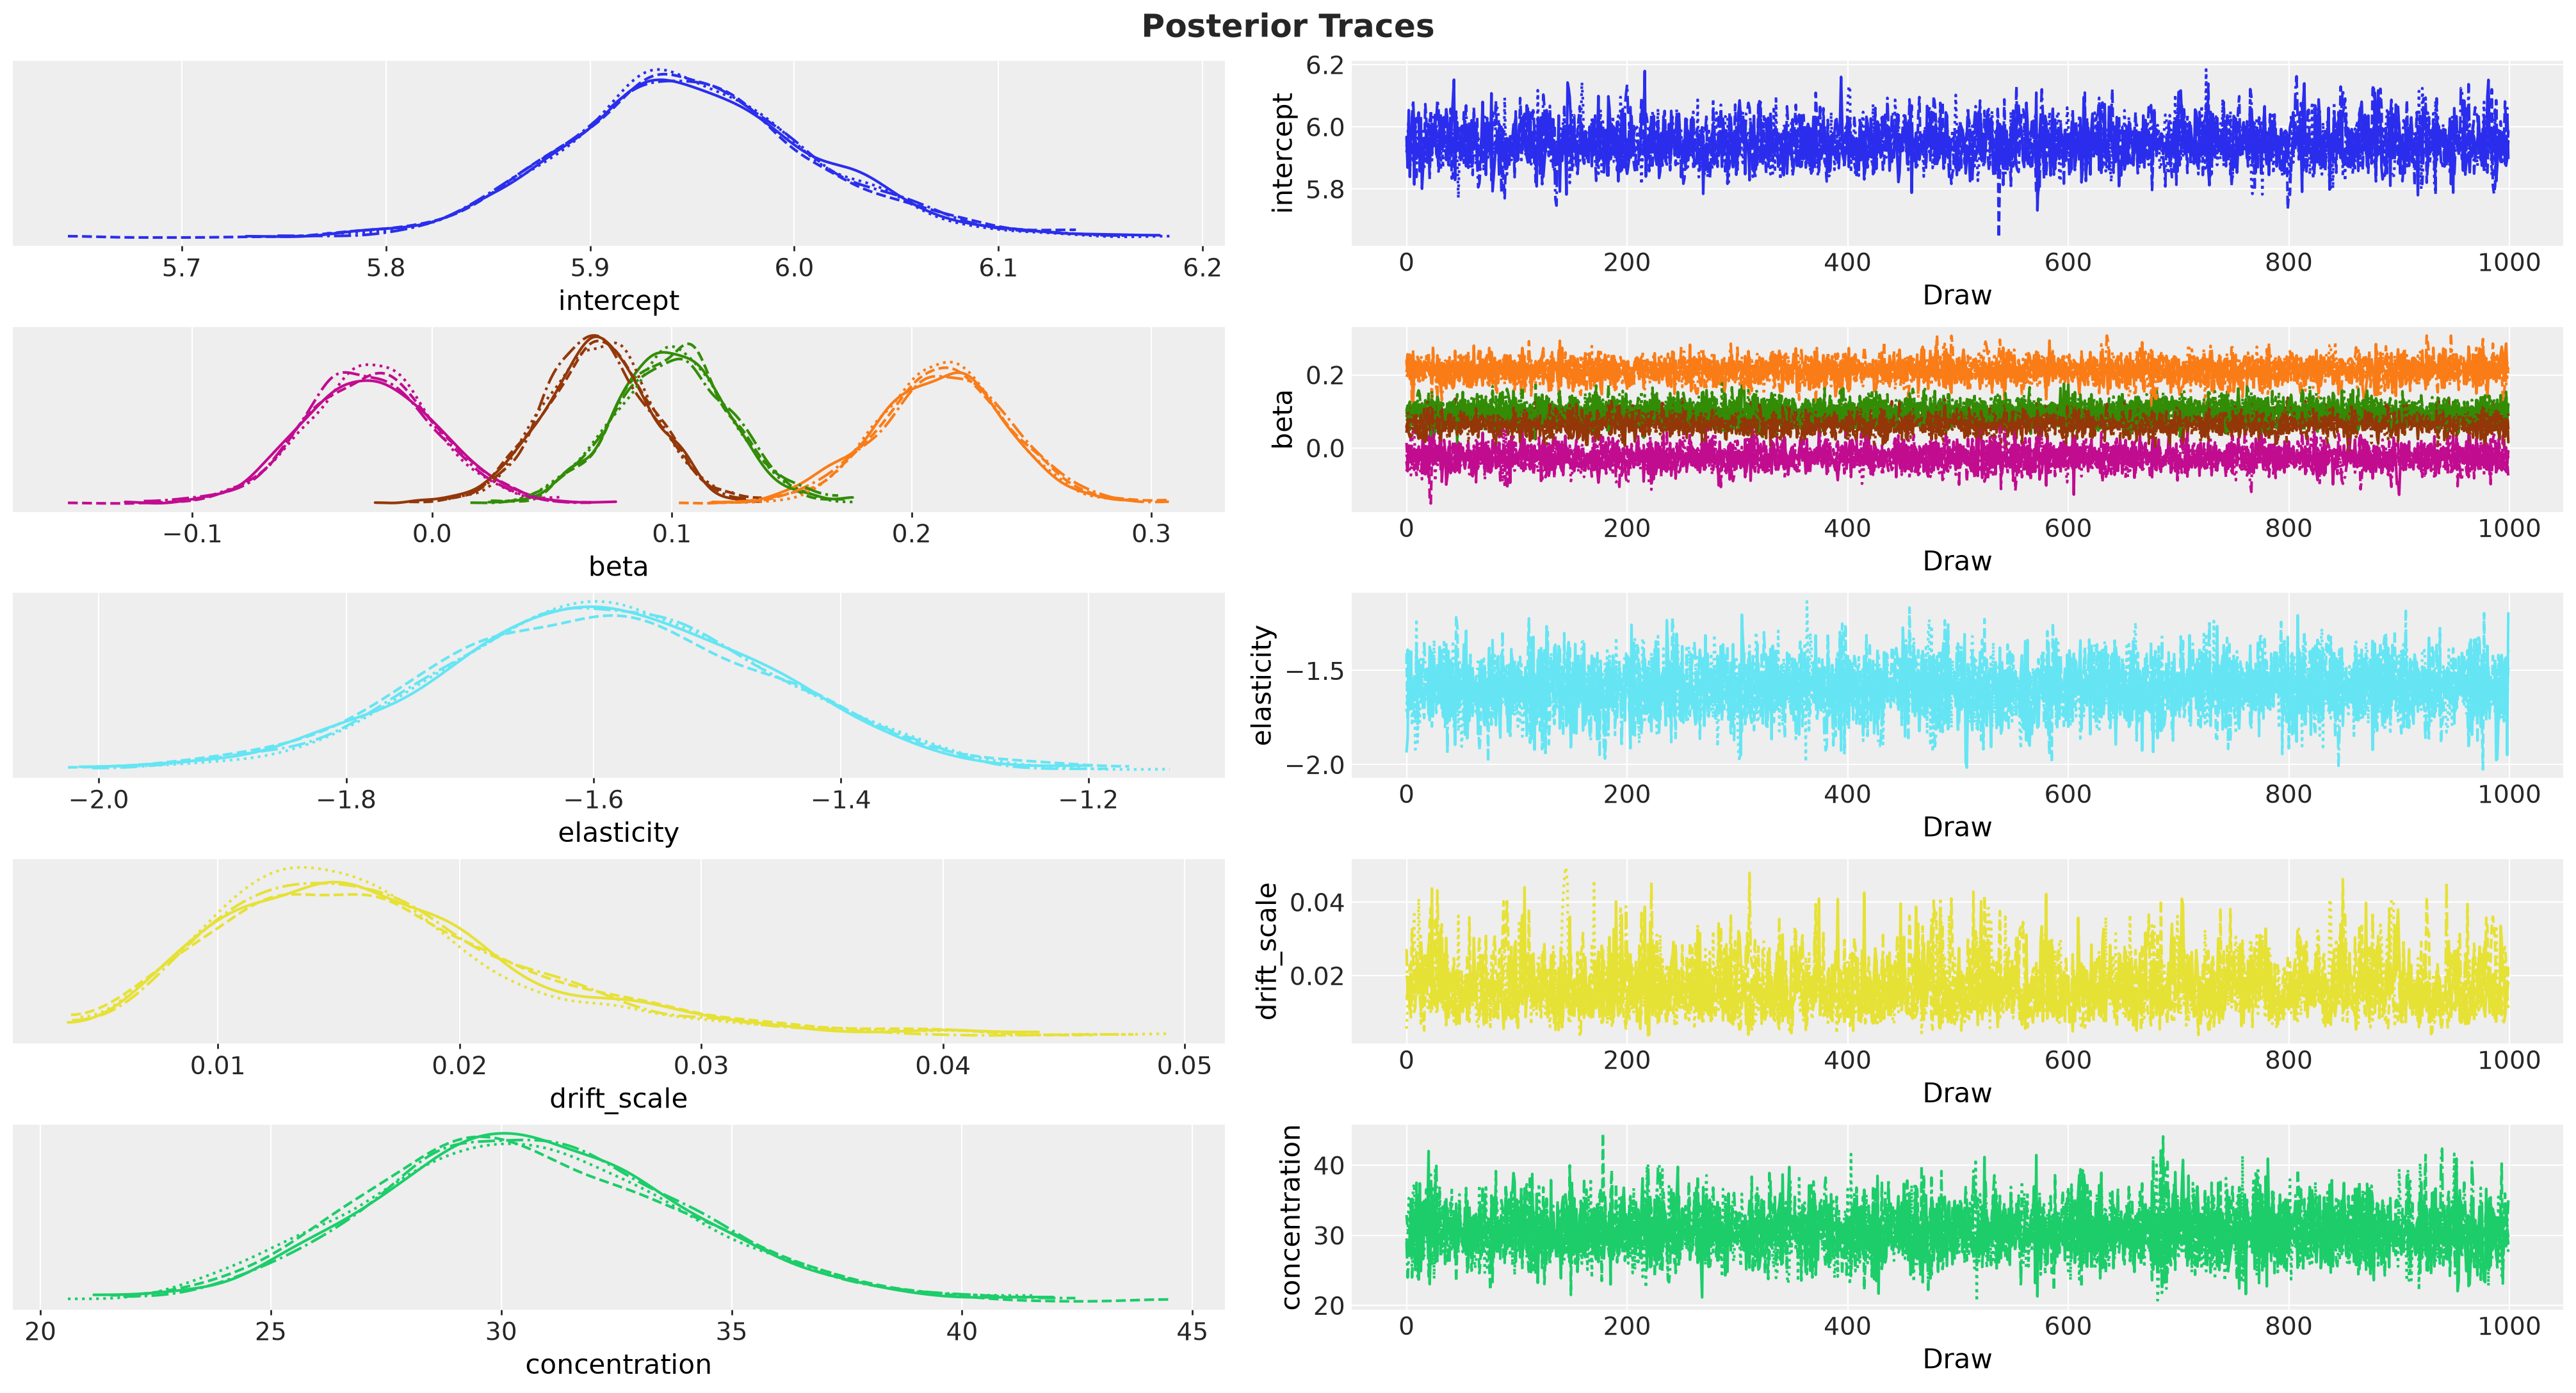

In [11]:
pc = az.plot_trace_dist(idata, var_names=global_params)
pc.viz["figure"].item().suptitle("Posterior Traces", fontsize=18, fontweight="bold");

The chains mix well. Next, we check that the posterior recovers the parameters we fixed in the generator. The dashed lines are the true values.

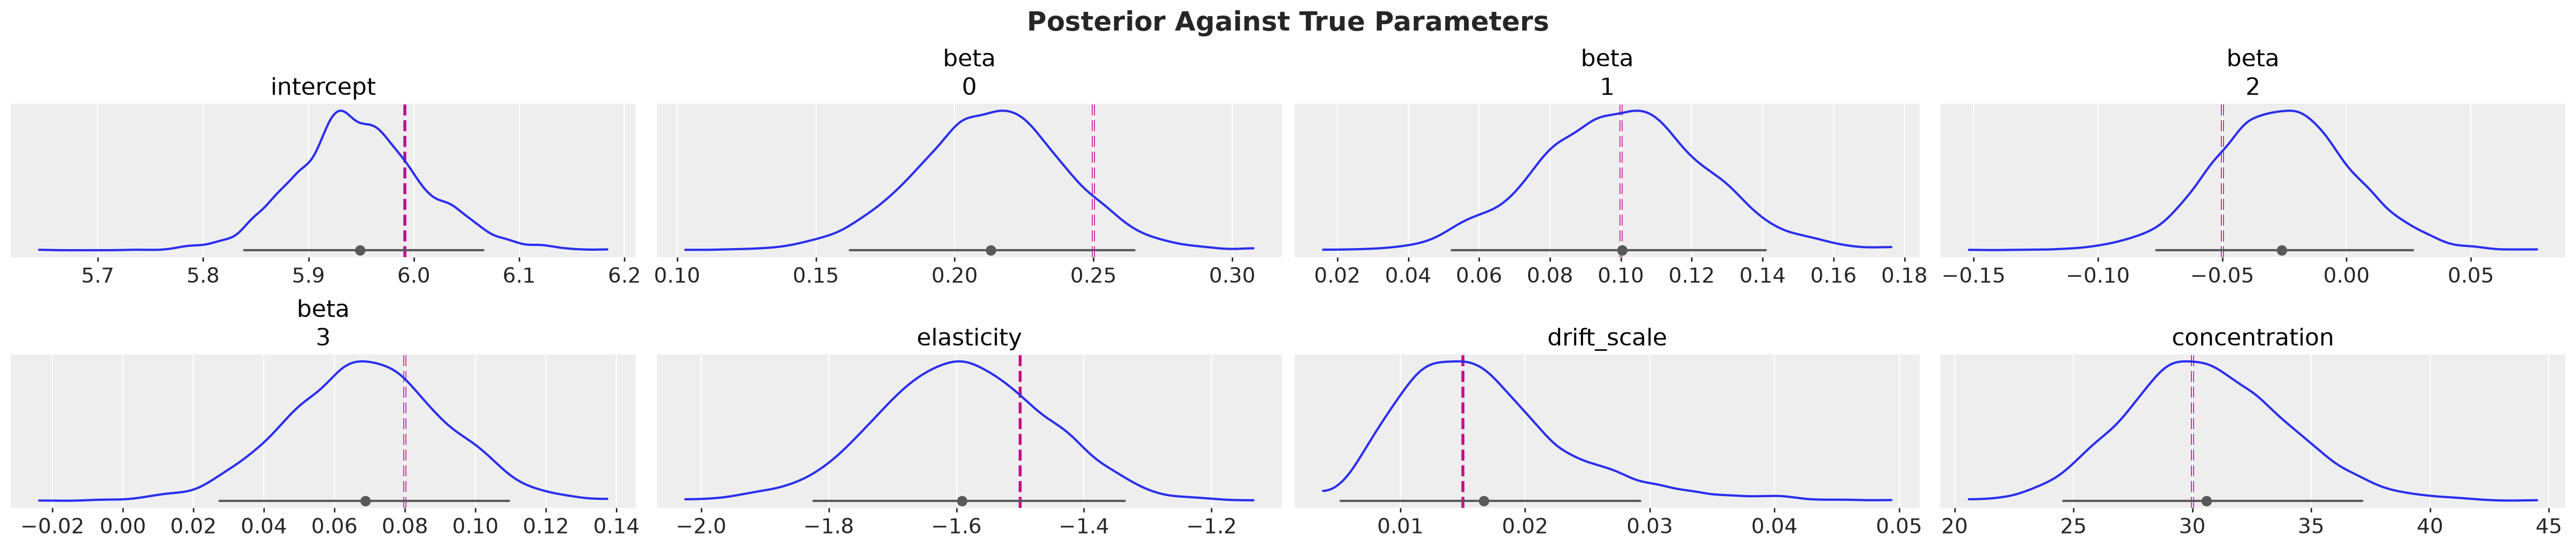

In [12]:
true_values = xr.Dataset(
    {
        "intercept": float(true_params["intercept"]),
        "beta": (idata["posterior"]["beta"].dims[-1], np.asarray(true_params["beta"])),
        "elasticity": float(true_params["elasticity"]),
        "drift_scale": float(true_params["drift_scale"]),
        "concentration": float(true_params["concentration"]),
    }
)

pc = az.plot_dist(
    idata,
    var_names=global_params,
    kind="kde",
    visuals={"point_estimate_text": False},
)
az.add_lines(
    pc,
    values=true_values,
    visuals={"ref_line": {"color": "C3", "linestyle": "--", "linewidth": 2}},
)
pc.viz["figure"].item().suptitle(
    "Posterior Against True Parameters", fontsize=18, fontweight="bold"
);

The true values sit inside the posterior mass for every parameter. The `elasticity` is identified from the promotion weeks in the history, which is what makes the price covariate useful over the horizon. Next, let's compare the in-sample posterior predictive distribution with the observed series over the last year of history.

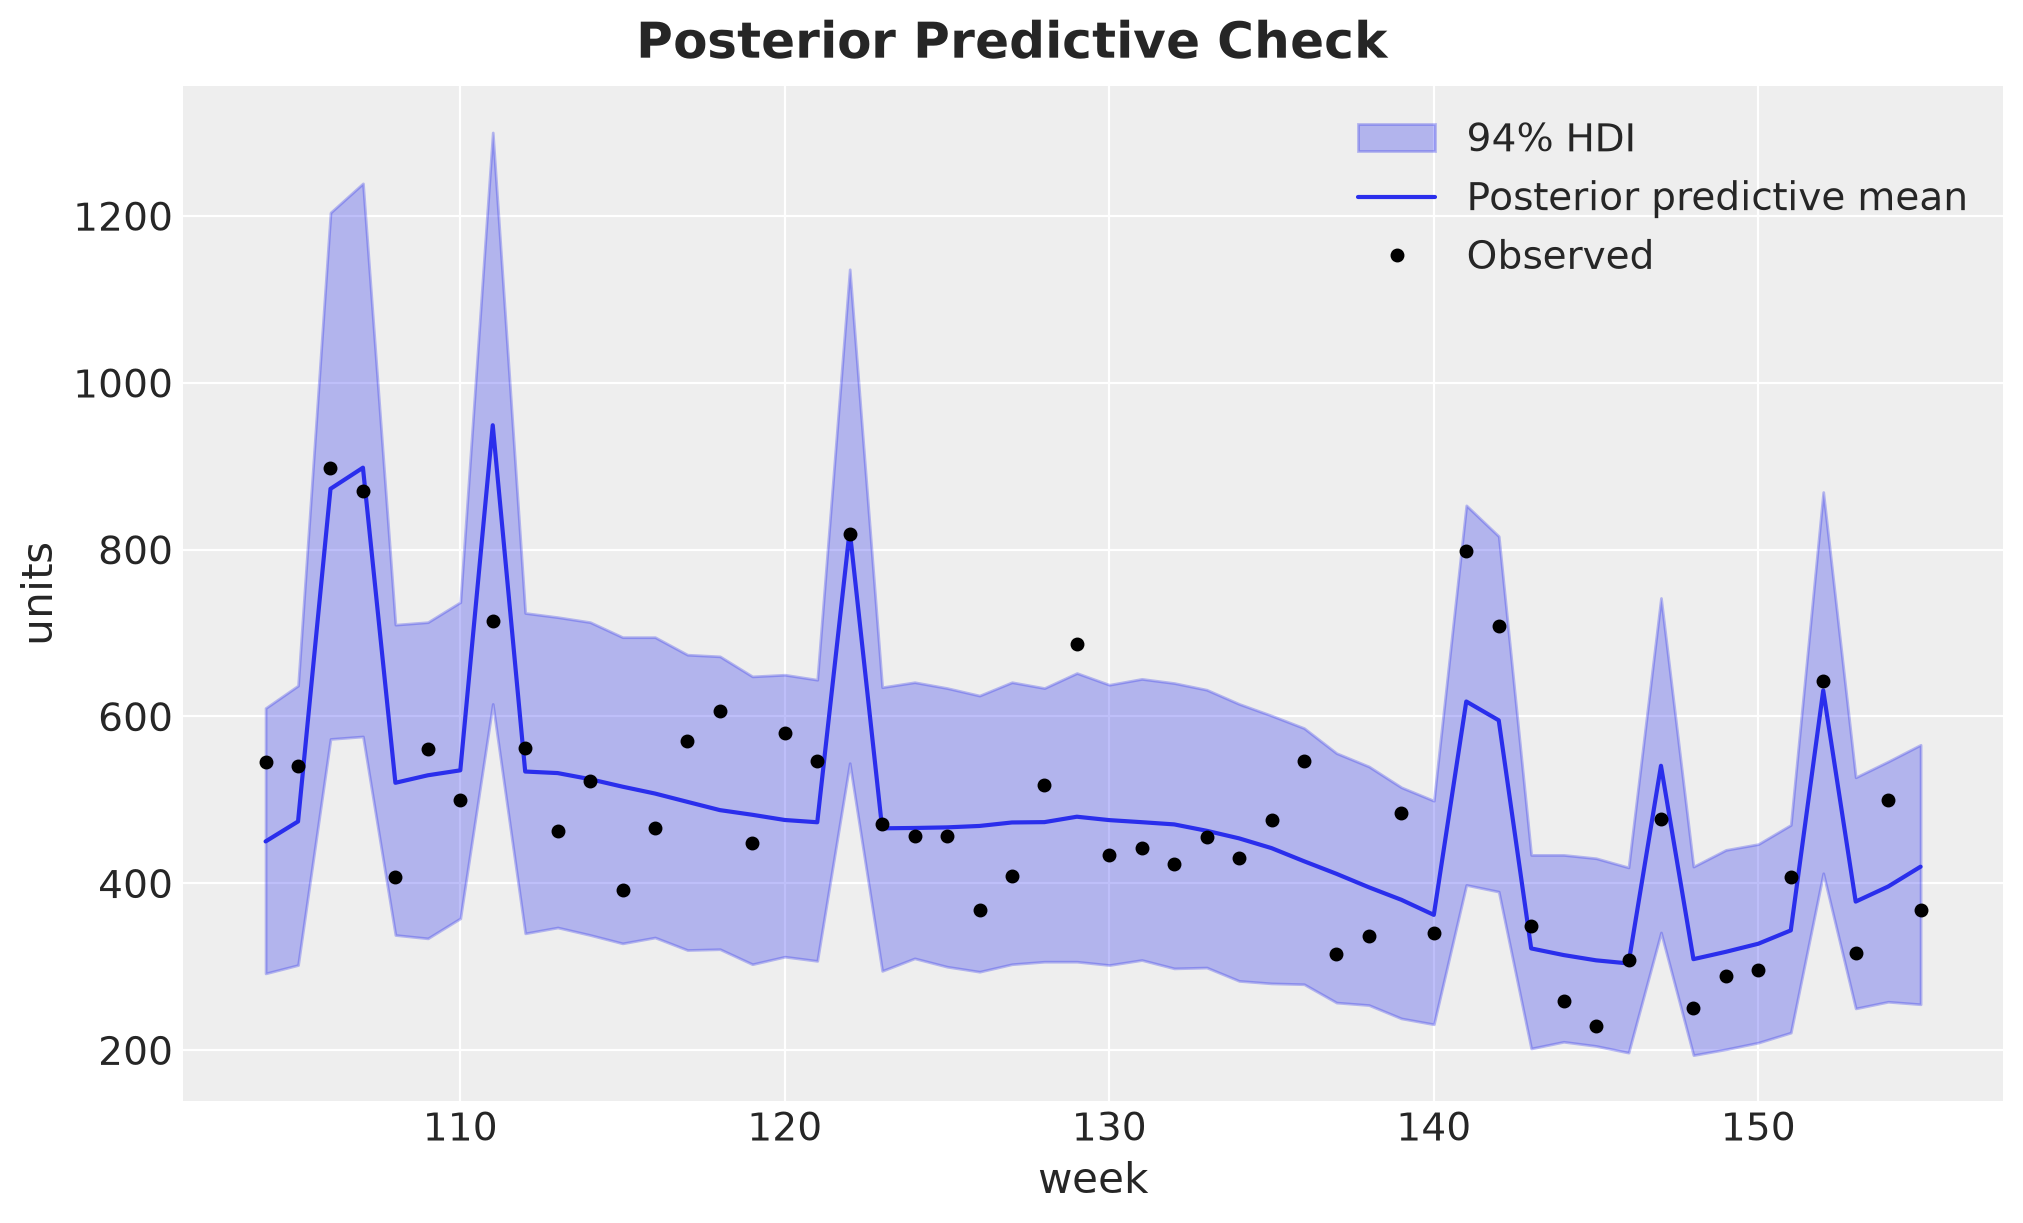

In [13]:
posterior_predictive = idata["posterior_predictive"]["obs"].sel(obs_dim=0)
ppc_mean = posterior_predictive.mean(("chain", "draw"))
ppc_hdi = az.hdi(posterior_predictive)
last_year = slice(T_OBS - 52, T_OBS)

fig, ax = plt.subplots()
ax.fill_between(
    weeks[last_year],
    ppc_hdi.sel(ci_bound="lower")[last_year],
    ppc_hdi.sel(ci_bound="upper")[last_year],
    color="C0",
    alpha=0.3,
    label=f"{HDI_PROB:.0%} HDI",
)
ax.plot(
    weeks[last_year], ppc_mean[last_year], color="C0", label="Posterior predictive mean"
)
ax.plot(
    weeks[last_year],
    np.asarray(data[last_year, 0]),
    "o",
    markersize=4,
    color="black",
    label="Observed",
)
ax.legend(loc="upper right")
ax.set(xlabel="week", ylabel="units")
fig.suptitle("Posterior Predictive Check", fontsize=18, fontweight="bold");

Nearly all observations sit inside the $94\%$ interval, and the mean tracks both the seasonal cycle and the promotion spikes. The model is a reasonable description of the history, so let's move to the horizon.

## Demand Scenarios

`to_datatree` stores the forecast draws as `obs` in the `predictions` group, shaped `(chain, draw, time, obs_dim)`. We flatten the sample dimensions into a scenario matrix of shape $(S, H)$, where each row is one *joint* draw of the $13$ weeks. Joint draws matter because the chance constraint needs quantiles of cumulative demand. Under independent weeks the errors would average out and the quantile of cumulative demand would be narrow. The shared level makes the weeks positively correlated, which widens that quantile, and only joint draws carry the correlation.

We then shuffle the rows and split them. The first $1{,}000$ scenarios are the optimization set that every plan sees. We hold out the remaining $3{,}000$ and use them only to score the plans.

In [14]:
N_SCENARIOS_OPT = 1_000

scenarios = jnp.asarray(
    idata["predictions"]["obs"].values.reshape(-1, HORIZON), dtype=jnp.float32
)
rng_key, key_split = random.split(rng_key)
scenarios = scenarios[random.permutation(key_split, scenarios.shape[0])]
demand_opt, demand_eval = scenarios[:N_SCENARIOS_OPT], scenarios[N_SCENARIOS_OPT:]
print(f"optimization set {demand_opt.shape}, evaluation set {demand_eval.shape}")

optimization set (1000, 13), evaluation set (3000, 13)


Let's plot the forecast as a fan on the left and $30$ individual scenarios on the right. The shaded columns are the promotion weeks in the horizon.

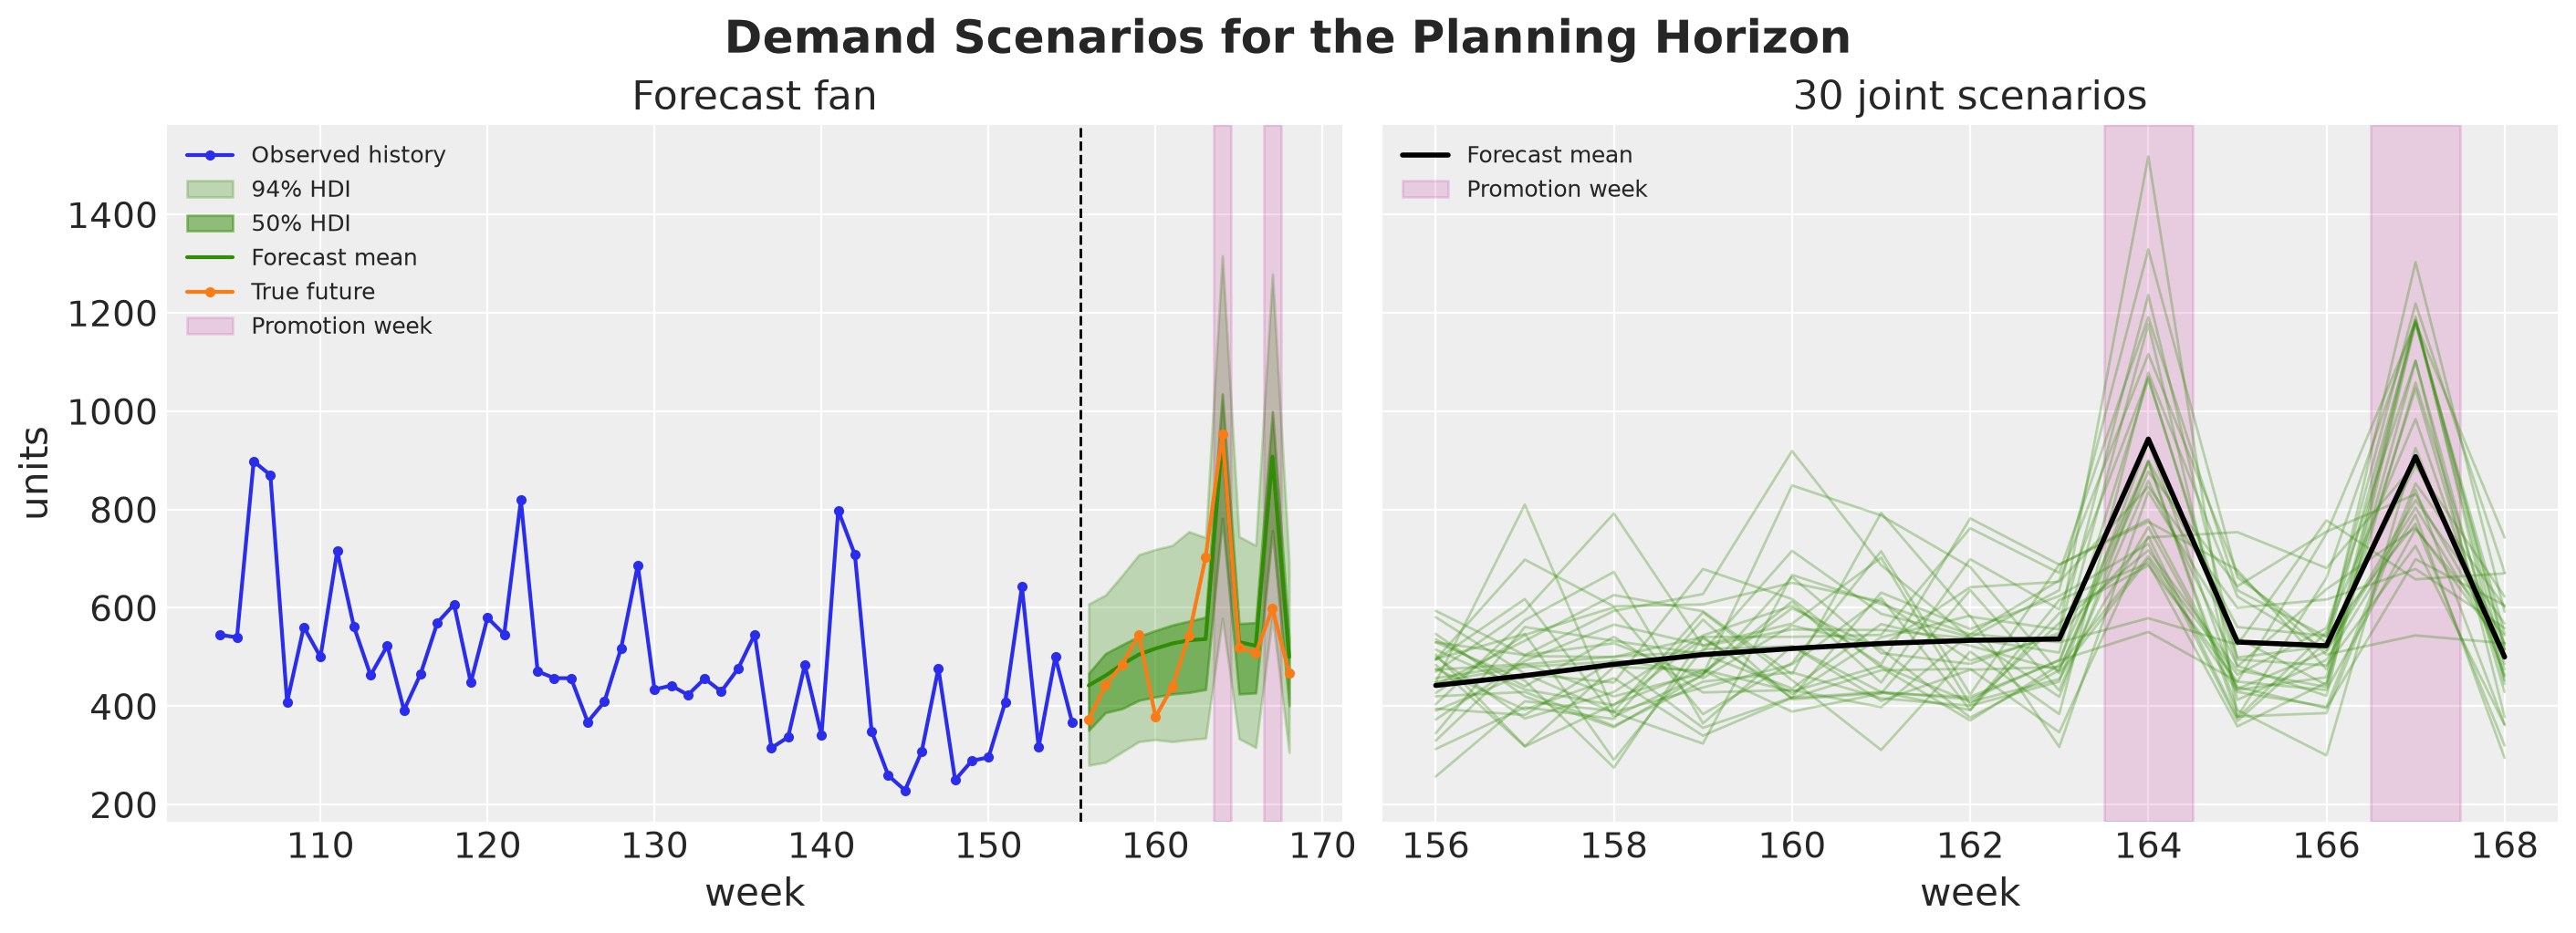

In [15]:
forecast_draws = idata["predictions"]["obs"].sel(obs_dim=0)
forecast_mean = forecast_draws.mean(("chain", "draw"))
hdi_wide = az.hdi(forecast_draws, prob=HDI_PROB)
hdi_narrow = az.hdi(forecast_draws, prob=0.50)
weeks_future = weeks[T_OBS:]

fig, axes = plt.subplots(ncols=2, figsize=(14, 5), sharey=True, layout="constrained")
ax = axes[0]
ax.plot(
    weeks[last_year],
    np.asarray(data[last_year, 0]),
    "o-",
    markersize=3,
    color="C0",
    label="Observed history",
)
ax.fill_between(
    weeks_future,
    hdi_wide.sel(ci_bound="lower"),
    hdi_wide.sel(ci_bound="upper"),
    color="C2",
    alpha=0.25,
    label=f"{HDI_PROB:.0%} HDI",
)
ax.fill_between(
    weeks_future,
    hdi_narrow.sel(ci_bound="lower"),
    hdi_narrow.sel(ci_bound="upper"),
    color="C2",
    alpha=0.5,
    label="50% HDI",
)
ax.plot(weeks_future, forecast_mean, color="C2", label="Forecast mean")
ax.plot(
    weeks_future,
    np.asarray(demand_future_true),
    "o-",
    markersize=3,
    color="C1",
    label="True future",
)
ax.axvline(T_OBS - 0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="week", ylabel="units", title="Forecast fan")
ax = axes[1]
ax.plot(weeks_future, np.asarray(demand_opt[:30]).T, color="C2", alpha=0.3, linewidth=1)
ax.plot(weeks_future, forecast_mean, color="black", linewidth=2, label="Forecast mean")
ax.set(xlabel="week", title="30 joint scenarios")

for ax in axes:
    for i, week in enumerate(promo_weeks_future):
        ax.axvspan(
            week - 0.5,
            week + 0.5,
            color="C3",
            alpha=0.15,
            label="Promotion week" if i == 0 else None,
        )

    ax.legend(loc="upper left", fontsize=9)

fig.suptitle(
    "Demand Scenarios for the Planning Horizon", fontsize=18, fontweight="bold"
);

The fan widens with the horizon because the level keeps drifting, and it jumps in the two promotion weeks because the model knows the price path. The individual paths on the right are what the optimizer sees: it scores a plan against each of them, and the functional decides how to aggregate those scores.

## Inventory Simulator

The loss $L(x, D)$ is a recursion over weeks, so we write it as a `jax.lax.scan` that carries the inventory position. Vectorizing over scenarios is one `jax.vmap` with `in_axes=(None, 0, None)`: the plan is shared, the demand path is batched. The `problem` tuple holds Python floats, so we mark it static under `jax.jit`. A `Scalar` is a float array with no axes.

In [16]:
Scalar = Float[Array, ""]


def simulate(
    orders: Float[Array, " horizon"], demand: Float[Array, " horizon"], problem: Problem
) -> tuple[Scalar, Float[Array, " horizon"]]:
    """Loss and inventory path of one plan against one demand path."""

    def step(
        inventory: Scalar, inputs: tuple[Scalar, Scalar]
    ) -> tuple[Scalar, tuple[Scalar, Scalar]]:
        order_t, demand_t = inputs
        inventory = inventory + order_t - demand_t
        cost_t = problem.holding_cost * jnp.maximum(
            inventory, 0.0
        ) + problem.backorder_cost * jnp.maximum(-inventory, 0.0)
        return inventory, (inventory, cost_t)

    initial_inventory = jnp.asarray(problem.initial_inventory, dtype=orders.dtype)
    _, (inventory_path, cost_path) = jax.lax.scan(
        step, initial_inventory, (orders, demand)
    )
    return cost_path.sum(), inventory_path


simulate_scenarios = jax.jit(
    jax.vmap(simulate, in_axes=(None, 0, None)), static_argnames="problem"
)

We also need the tail average. For $S$ equally weighted scenarios, $\text{CVaR}_\alpha$ is the mean of the $k = \alpha S$ largest losses, which `jax.lax.top_k` selects in one call. We keep $k$ as a Python integer so that the shape is static.

In [17]:
def cvar(losses: Float[Array, " scenarios"], alpha: float) -> Scalar:
    """Mean of the worst alpha fraction of the losses."""
    k = round(alpha * losses.shape[0])
    worst, _ = jax.lax.top_k(losses, k)
    return worst.mean()

Let's run a quick sanity check: a plan that orders exactly the mean demand every week, scored on the optimization set. We keep the mean demand path, since several cells below use it.

In [18]:
mean_demand_opt = demand_opt.mean(axis=0)
losses_check, inventory_check = simulate_scenarios(mean_demand_opt, demand_opt, problem)
print(f"expected loss {float(losses_check.mean()):,.0f}")
print(f"CVaR {float(cvar(losses_check, problem.alpha)):,.0f}")
print(f"shape of the inventory paths {inventory_check.shape}")

expected loss 3,572
CVaR 18,598
shape of the inventory paths (1000, 13)


## Decision Plans

### Mean Forecast Plan

Against a single demand path the cheapest plan keeps the inventory at zero: cumulative orders equal cumulative demand minus the initial stock, clipped at zero. The same function also gives the chance-constrained plan, with a quantile path instead of the mean path. `jax.lax.cummax` keeps the cumulative orders non-decreasing, so every weekly order is non-negative. For a non-decreasing target the `cummax` never binds, and the clip at zero binds only when the week one target is below $I_0$, which is not the case here.

In [19]:
def plan_from_cumulative_target(
    target_cumulative_demand: Float[Array, " horizon"], problem: Problem
) -> Float[Array, " horizon"]:
    """Weekly orders that keep cumulative orders at the target cumulative demand."""
    cumulative_orders = jax.lax.cummax(
        jnp.maximum(target_cumulative_demand - problem.initial_inventory, 0.0), axis=0
    )
    return jnp.diff(cumulative_orders, prepend=0.0)


cumulative_demand_opt = jnp.cumsum(demand_opt, axis=1)
orders_mean = plan_from_cumulative_target(cumulative_demand_opt.mean(axis=0), problem)
print("mean forecast plan:", np.round(np.asarray(orders_mean)).astype(int))

mean forecast plan: [141 467 488 504 519 531 537 534 929 530 526 906 501]


Let's score this plan on the mean path and on the optimization scenarios.

In [20]:
loss_on_mean_path, _ = simulate(orders_mean, mean_demand_opt, problem)
losses_mean_plan, _ = simulate_scenarios(orders_mean, demand_opt, problem)
print(f"loss on the mean path {float(loss_on_mean_path):,.0f}")
print(f"expected loss over the scenarios {float(losses_mean_plan.mean()):,.0f}")

loss on the mean path 0
expected loss over the scenarios 6,245


Observe that this plan has zero cost on the mean path and an expected loss of about $6{,}200$ over the scenarios. The sanity check above cost $3{,}600$ because it kept the $300$ initial units as a permanent buffer. Running the mean path at zero inventory nearly doubles the expected loss.

### Chance-Constrained Plan

We replace the mean path by the $(1 - \alpha)$ quantile of cumulative demand, computed across the joint scenarios. By construction the plan covers demand in at least $95\%$ of the optimization scenarios in every week.

In [21]:
quantile_path = jnp.quantile(cumulative_demand_opt, 1 - problem.alpha, axis=0)
orders_cc = plan_from_cumulative_target(quantile_path, problem)
print("chance-constrained plan:", np.round(np.asarray(orders_cc)).astype(int))

chance-constrained plan: [ 292  540  567  595  571  594  613  584 1105  606  639 1010  549]


### Expected Cost Plan

Only the CVaR plan needs an optimizer, and we solve the $\lambda = 0$ case with it as well so that the linear program below checks both solves. The objective $\text{E}[L] + \lambda \, \text{CVaR}_\alpha(L)$ is convex in $x$ (a sum of hinge terms of linear functions, and a tail average of such sums), and the only constraint is $x \geq 0$. We use projected gradient descent with Adam: after each step we clip the orders at zero, which is the Euclidean projection onto the feasible set. The whole optimization loop is a `jax.lax.scan` inside `jax.jit`, so there is no Python overhead per step, and the same function vectorizes over $\lambda$ with `jax.vmap`.

The objective is piecewise linear, so the gradient is a subgradient. A cosine decay of the learning rate makes the iterates settle, and we confirm the optimum against a linear program below.

In [22]:
def objective(
    orders: Float[Array, " horizon"],
    demand: Float[Array, "scenarios horizon"],
    lam: ScalarLike,
    problem: Problem,
) -> Scalar:
    """Expected loss plus lam times the CVaR of the loss over the scenarios."""
    losses, _ = simulate_scenarios(orders, demand, problem)
    return losses.mean() + lam * cvar(losses, problem.alpha)


def solve(
    demand: Float[Array, "scenarios horizon"],
    lam: ScalarLike,
    orders_init: Float[Array, " horizon"],
    problem: Problem,
    n_steps: int = 3_000,
    learning_rate: float = 5.0,
) -> tuple[Float[Array, " horizon"], Float[Array, " n_steps"]]:
    """Projected Adam on the expected cost plus lam times CVaR, as a lax.scan."""
    optimizer = optax.adam(
        optax.cosine_decay_schedule(learning_rate, n_steps, alpha=0.01)
    )
    value_and_grad = jax.value_and_grad(objective)

    def step(
        carry: tuple[Float[Array, " horizon"], optax.OptState], _: None
    ) -> tuple[tuple[Float[Array, " horizon"], optax.OptState], Scalar]:
        orders, opt_state = carry
        value, grads = value_and_grad(orders, demand, lam, problem)
        updates, opt_state = optimizer.update(grads, opt_state, orders)
        orders = jnp.maximum(orders + updates, 0.0)  # projection onto x >= 0
        return (orders, opt_state), value

    (orders, _), trace = jax.lax.scan(
        step, (orders_init, optimizer.init(orders_init)), None, length=n_steps
    )
    return orders, trace


solve_jit = jax.jit(solve, static_argnames=("problem", "n_steps"))

We start from the mean forecast plan and set $\lambda = 0$. We also build the newsvendor plan in closed form, with the $0.909$ quantile path in place of the $0.95$ one, and compare the two.

In [23]:
orders_saa, trace_saa = solve_jit(demand_opt, 0.0, orders_mean, problem)
print("expected cost plan:", np.round(np.asarray(orders_saa)).astype(int))
print(f"objective {float(trace_saa[-1]):,.1f}")

newsvendor_path = jnp.quantile(cumulative_demand_opt, critical_fractile, axis=0)
orders_newsvendor = plan_from_cumulative_target(newsvendor_path, problem)
print("newsvendor plan:  ", np.round(np.asarray(orders_newsvendor)).astype(int))
print(
    f"max order difference {float(jnp.abs(orders_saa - orders_newsvendor).max()):.0f}"
)

expected cost plan: [ 259  530  550  567  564  596  594  596 1065  582  562 1014  547]
objective 2,737.3


newsvendor plan:   [ 259  530  550  566  565  594  591  601 1063  583  561 1016  539]
max order difference 8


The optimizer lands within $8$ units of the closed form, so the two constructions agree. The expected cost plan is a quantile plan at the critical fractile, and the chance-constrained plan is the same construction at $0.95$.

### CVaR Plan

Now we put a price on the tail with $\lambda = 1$: one dollar of average loss in the worst $5\%$ of scenarios counts as much as one dollar of expected loss.

In [24]:
orders_cvar, trace_cvar = solve_jit(demand_opt, 1.0, orders_mean, problem)
print("CVaR plan:", np.round(np.asarray(orders_cvar)).astype(int))
print(f"objective {float(trace_cvar[-1]):,.1f}")

CVaR plan: [ 271  519  567  607  646  692  653  637 1109  739  622  827  603]
objective 9,299.1


Let's look at the optimization traces for both solves.

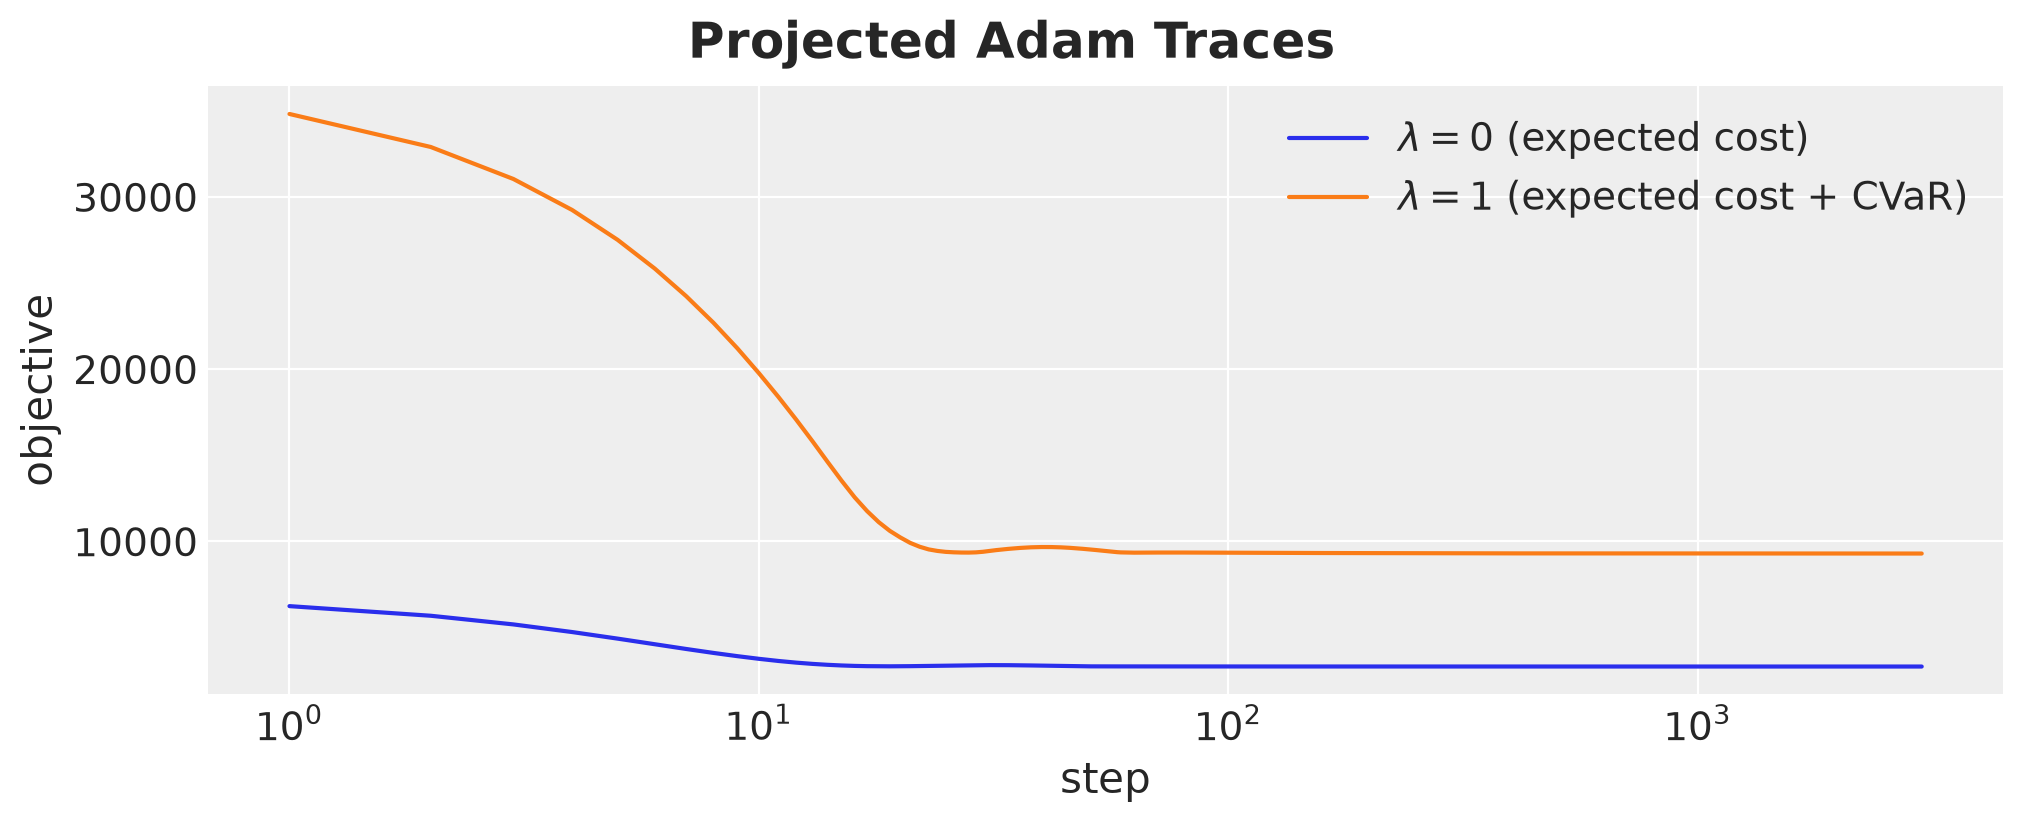

In [25]:
steps = np.arange(1, trace_saa.shape[0] + 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    steps, np.asarray(trace_saa), color="C0", label=r"$\lambda = 0$ (expected cost)"
)
ax.plot(
    steps,
    np.asarray(trace_cvar),
    color="C1",
    label=r"$\lambda = 1$ (expected cost + CVaR)",
)
ax.set(xlabel="step", ylabel="objective", xscale="log")
ax.legend()
fig.suptitle("Projected Adam Traces", fontsize=18, fontweight="bold");

Both objectives drop within the first $30$ steps and stay flat for the rest of the schedule, whose decay only removes the residual oscillation. The expected cost objective settles at $2{,}737$ and the CVaR objective at $9{,}299$. We now have the four plans, so let's compare them. The shaded columns are again the promotion weeks.

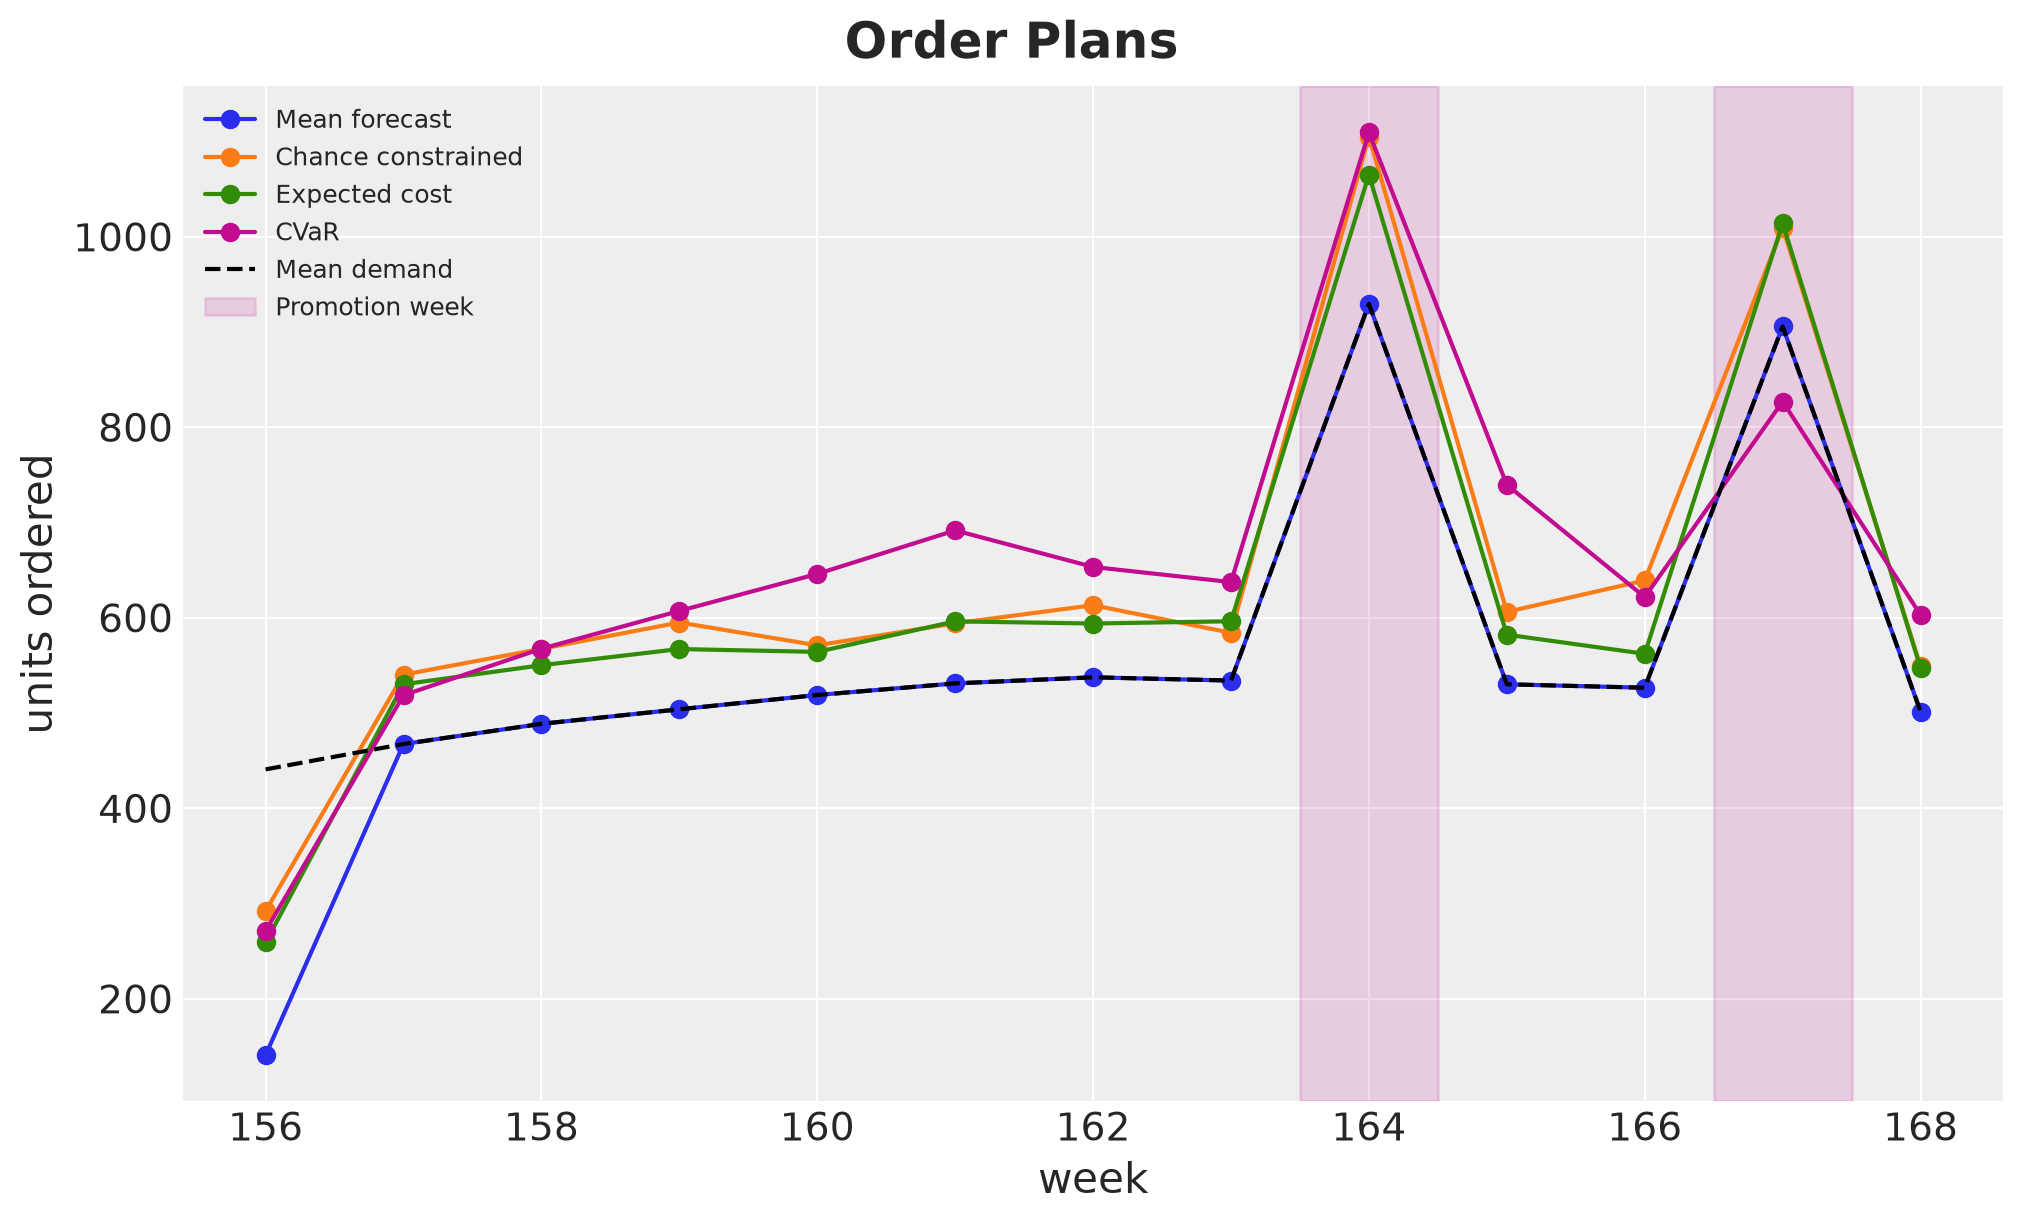

In [26]:
plans = {
    "Mean forecast": orders_mean,
    "Chance constrained": orders_cc,
    "Expected cost": orders_saa,
    "CVaR": orders_cvar,
}

fig, ax = plt.subplots()

for i, (name, orders) in enumerate(plans.items()):
    ax.plot(weeks_future, np.asarray(orders), "o-", color=f"C{i}", label=name)

ax.plot(
    weeks_future,
    np.asarray(mean_demand_opt),
    color="black",
    linestyle="--",
    label="Mean demand",
)

for i, week in enumerate(promo_weeks_future):
    ax.axvspan(
        week - 0.5,
        week + 0.5,
        color="C3",
        alpha=0.15,
        label="Promotion week" if i == 0 else None,
    )

ax.legend(loc="upper left", fontsize=9)
ax.set(xlabel="week", ylabel="units ordered")
fig.suptitle("Order Plans", fontsize=18, fontweight="bold");

The mean forecast plan follows the mean demand, with a small first order because the initial stock covers most of week one. The three other plans order a buffer above the mean from the first week on, and every plan orders more in the two promotion weeks.

The buffer is large because every plan is fixed in advance, so it has to hedge the uncertainty of cumulative demand over the whole quarter, and because the holding cost is one tenth of the backorder cost.

The CVaR plan carries the largest buffer in the middle of the quarter and orders ahead of the second promotion instead of in it. The tail objective is nearly flat along shifts of units between neighboring weeks, so the solver stops anywhere on that flat region.

## Out of Sample Evaluation

We score every plan on the $3{,}000$ held-out scenarios. Besides the expected loss and the tail average, we report the stockout probability per week (the fraction of scenario and week pairs with a backlog) and the probability of at least one stockout in the quarter. We simulate each plan once and keep the losses and the inventory paths for the figures below.

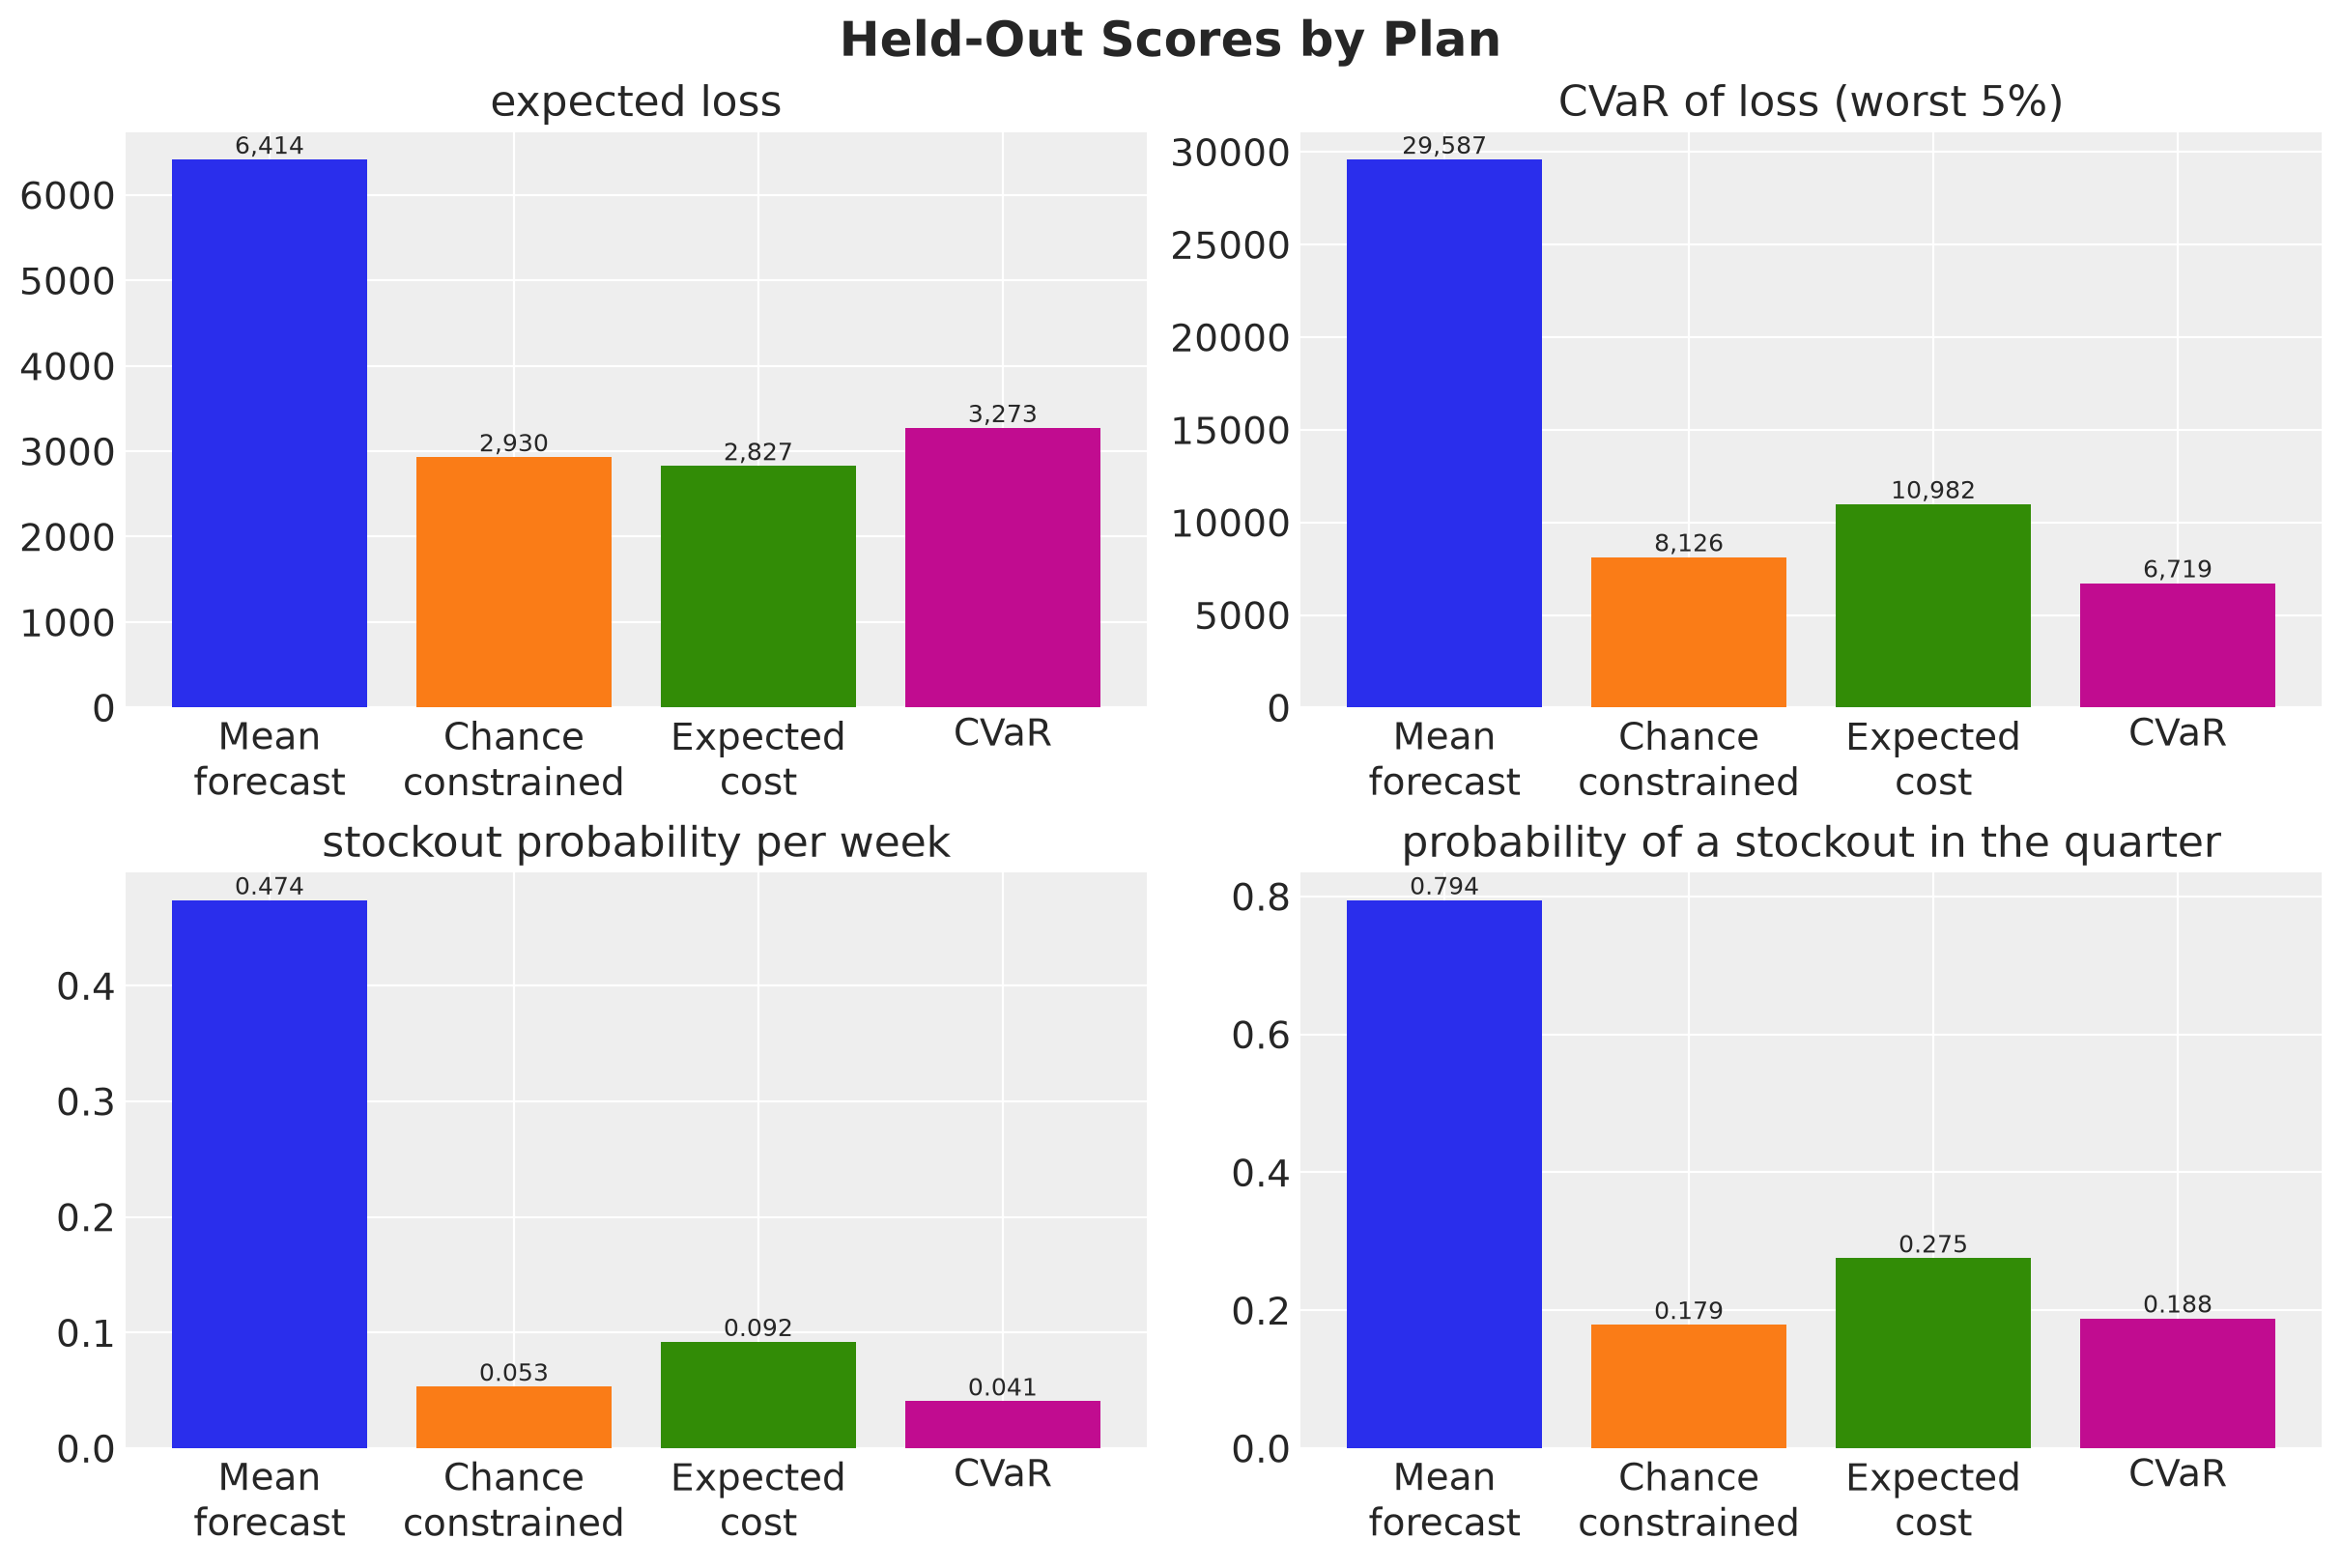

In [27]:
def summarize(
    losses: Float[Array, " scenarios"],
    inventory: Float[Array, "scenarios horizon"],
    alpha: float,
) -> dict[str, float]:
    """Expected loss, CVaR and stockout frequencies of one plan over the scenarios."""
    return {
        "expected_loss": float(losses.mean()),
        "cvar_loss": float(cvar(losses, alpha)),
        "stockout_prob_week": float((inventory < 0).mean()),
        "stockout_prob_quarter": float((inventory < 0).any(axis=1).mean()),
    }


scores = {
    name: simulate_scenarios(orders, demand_eval, problem)
    for name, orders in plans.items()
}
results = pl.DataFrame(
    [
        {"plan": name, **summarize(*score, problem.alpha)}
        for name, score in scores.items()
    ]
)

metric_labels = {
    "expected_loss": "expected loss",
    "cvar_loss": "CVaR of loss (worst 5%)",
    "stockout_prob_week": "stockout probability per week",
    "stockout_prob_quarter": "probability of a stockout in the quarter",
}
plan_colors = [f"C{i}" for i in range(len(plans))]
plan_labels = [name.replace(" ", "\n") for name in plans]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8), layout="constrained")

for ax, (metric, label) in zip(axes.flat, metric_labels.items(), strict=True):
    bars = ax.bar(plan_labels, results[metric].to_numpy(), color=plan_colors)
    ax.bar_label(bars, fmt="{:.3f}" if "prob" in metric else "{:,.0f}", fontsize=9)
    ax.set(title=label)

fig.suptitle("Held-Out Scores by Plan", fontsize=18, fontweight="bold");

Here are three important remarks.

- **The point forecast is expensive.** The mean forecast plan has the worst expected loss ($6{,}414$) and the worst tail ($29{,}587$), and it runs out of stock in about half of the weeks. Its zero cost on the mean path told us nothing about its cost on the distribution.
- **The expected cost plan lands on the critical fractile.** Its weekly stockout probability is $9.2\%$, close to $1 - p / (p + h) = 9.1\%$. That is the risk-neutral answer, and it follows from the costs alone.
- **The chance constraint and CVaR buy reliability differently.** The chance-constrained plan lands at $5.3\%$ on the held-out scenarios, close to its $5\%$ target. The CVaR plan with $\lambda = 1$ pushes the stockout probability down to $4.1\%$ and the tail loss down to $6{,}719$, and pays for it with the highest expected loss of the three ($3{,}273$). The per-quarter panel reverses the comparison: $18.8\%$ of the CVaR quarters and $17.9\%$ of the chance-constrained quarters see at least one stockout, so the CVaR plan spreads fewer stockout weeks over slightly more quarters. The frontier below shows the trade-off between these metrics.

Let's look at the loss distributions behind these numbers. We leave out the mean forecast plan, whose losses run to about $58{,}000$, one and a half times the largest loss of the other three, and we clip the horizontal axis at the $99$th percentile of the pooled losses to see the bulk of the distributions.

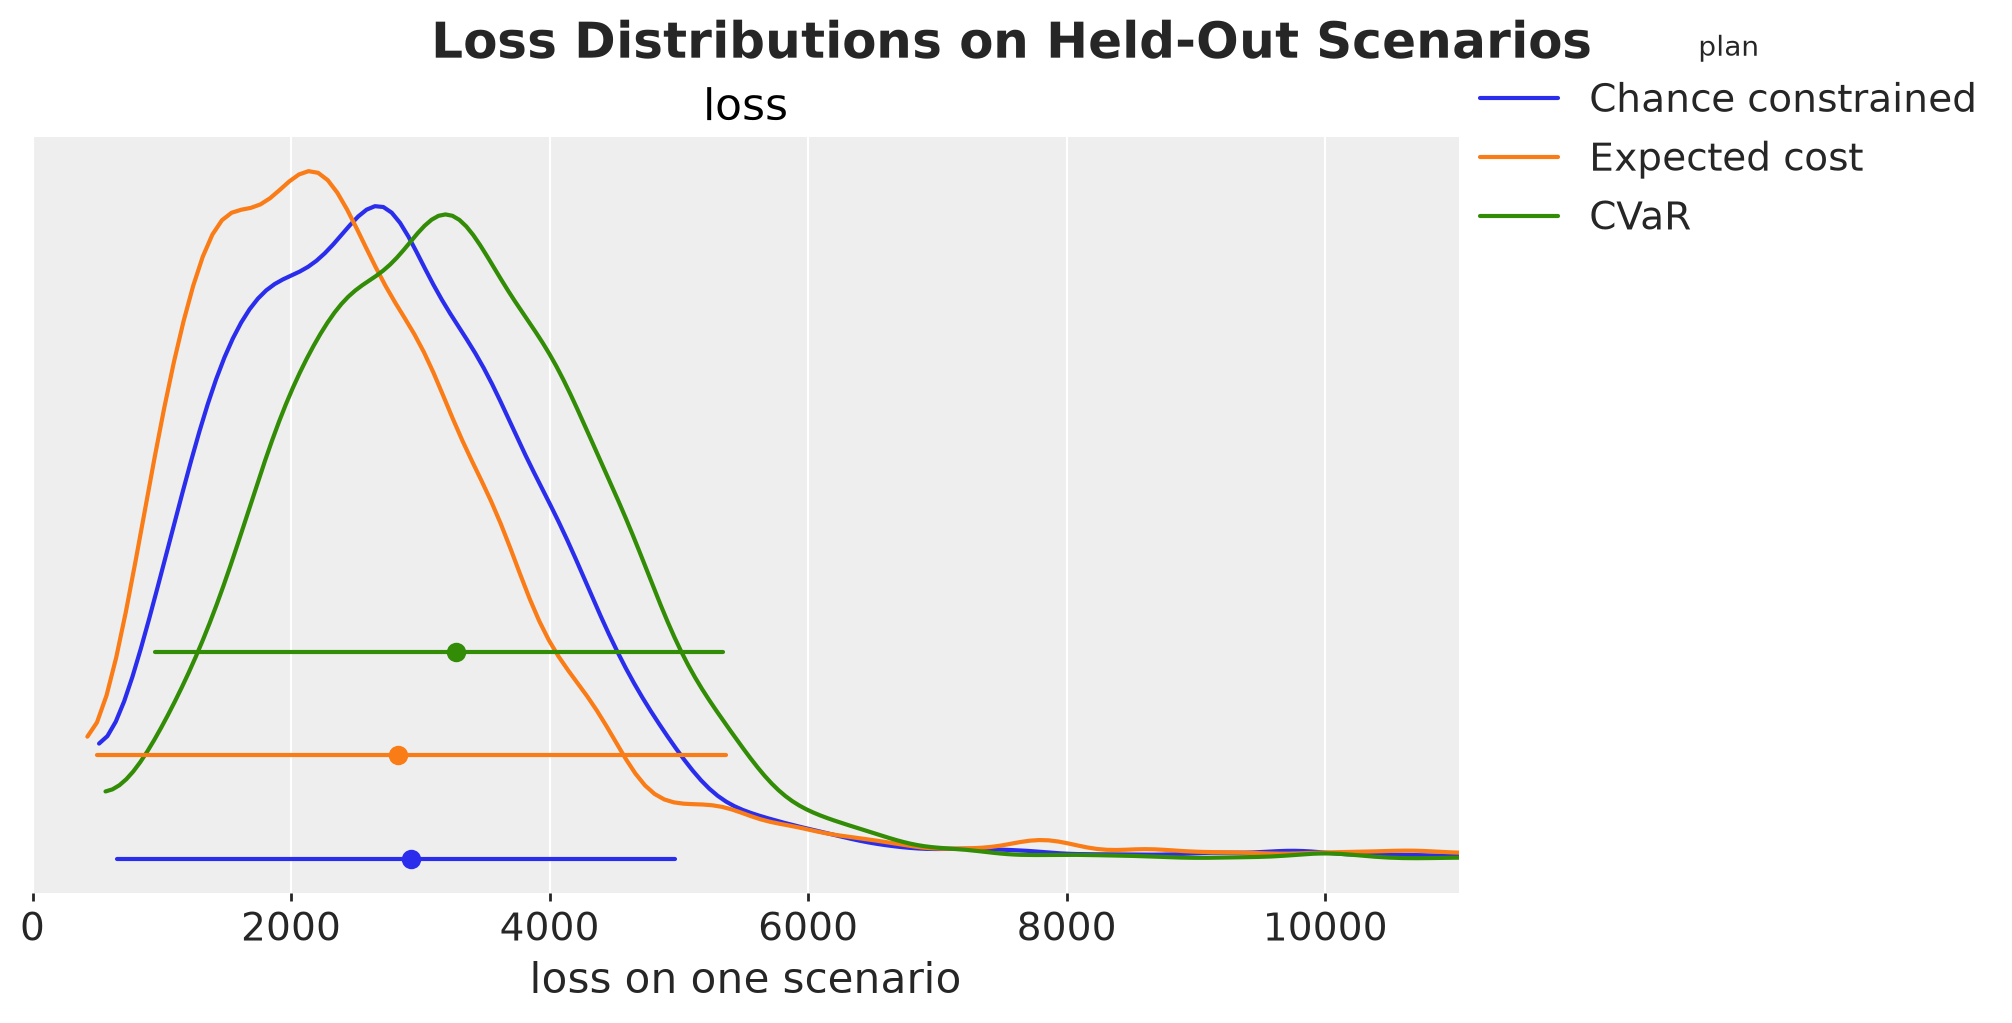

In [28]:
losses_by_plan = {
    name: xr.Dataset({"loss": (("sample",), np.asarray(losses))})
    for name, (losses, _) in scores.items()
    if name != "Mean forecast"
}
loss_clip = float(
    np.quantile(
        np.concatenate([ds["loss"].values for ds in losses_by_plan.values()]), 0.99
    )
)

pc = az.plot_dist(
    losses_by_plan,
    sample_dims=["sample"],
    kind="kde",
    visuals={"point_estimate_text": False},
    figure_kwargs={"figsize": (10, 5)},
)
pc.add_legend("model", title="plan")
pc.viz["plot"]["loss"].item().set(xlim=(0, loss_clip), xlabel="loss on one scenario")
pc.viz["figure"].item().suptitle(
    "Loss Distributions on Held-Out Scenarios", fontsize=18, fontweight="bold"
);

The expected cost plan has the most mass at low losses, and the bar chart above showed that it also has the heaviest right tail: its largest held-out loss is about $38{,}000$, as the scatter below shows. The CVaR plan trades some of that low-loss mass for a shorter tail, with a largest loss of about $28{,}000$, and the chance-constrained plan sits in between. The dots and bars are the means and $94\%$ intervals.

Why are the right tails so much longer than the left? The loss is bounded below by zero, and the two arms of the loss have different slopes.

One unit of demand less than planned in week $t$ stays on the shelf for the remaining $H - t + 1$ weeks and costs about $h \, (H - t + 1)$ in holding. One unit more than planned stays in backlog for the same weeks and costs about $p \, (H - t + 1)$. Both effects persist for the same number of weeks, so persistence is symmetric and the asymmetry comes from the cost ratio $p / h = 10$.

The plans sit above the mean demand, so most scenarios land on the cheap holding arm and a minority lands on the expensive backorder arm. A second source is the right skew of the scenarios themselves, because the level enters the rate through an exponential.

Let's confirm this by plotting the loss of every held-out scenario against its total demand in the quarter.

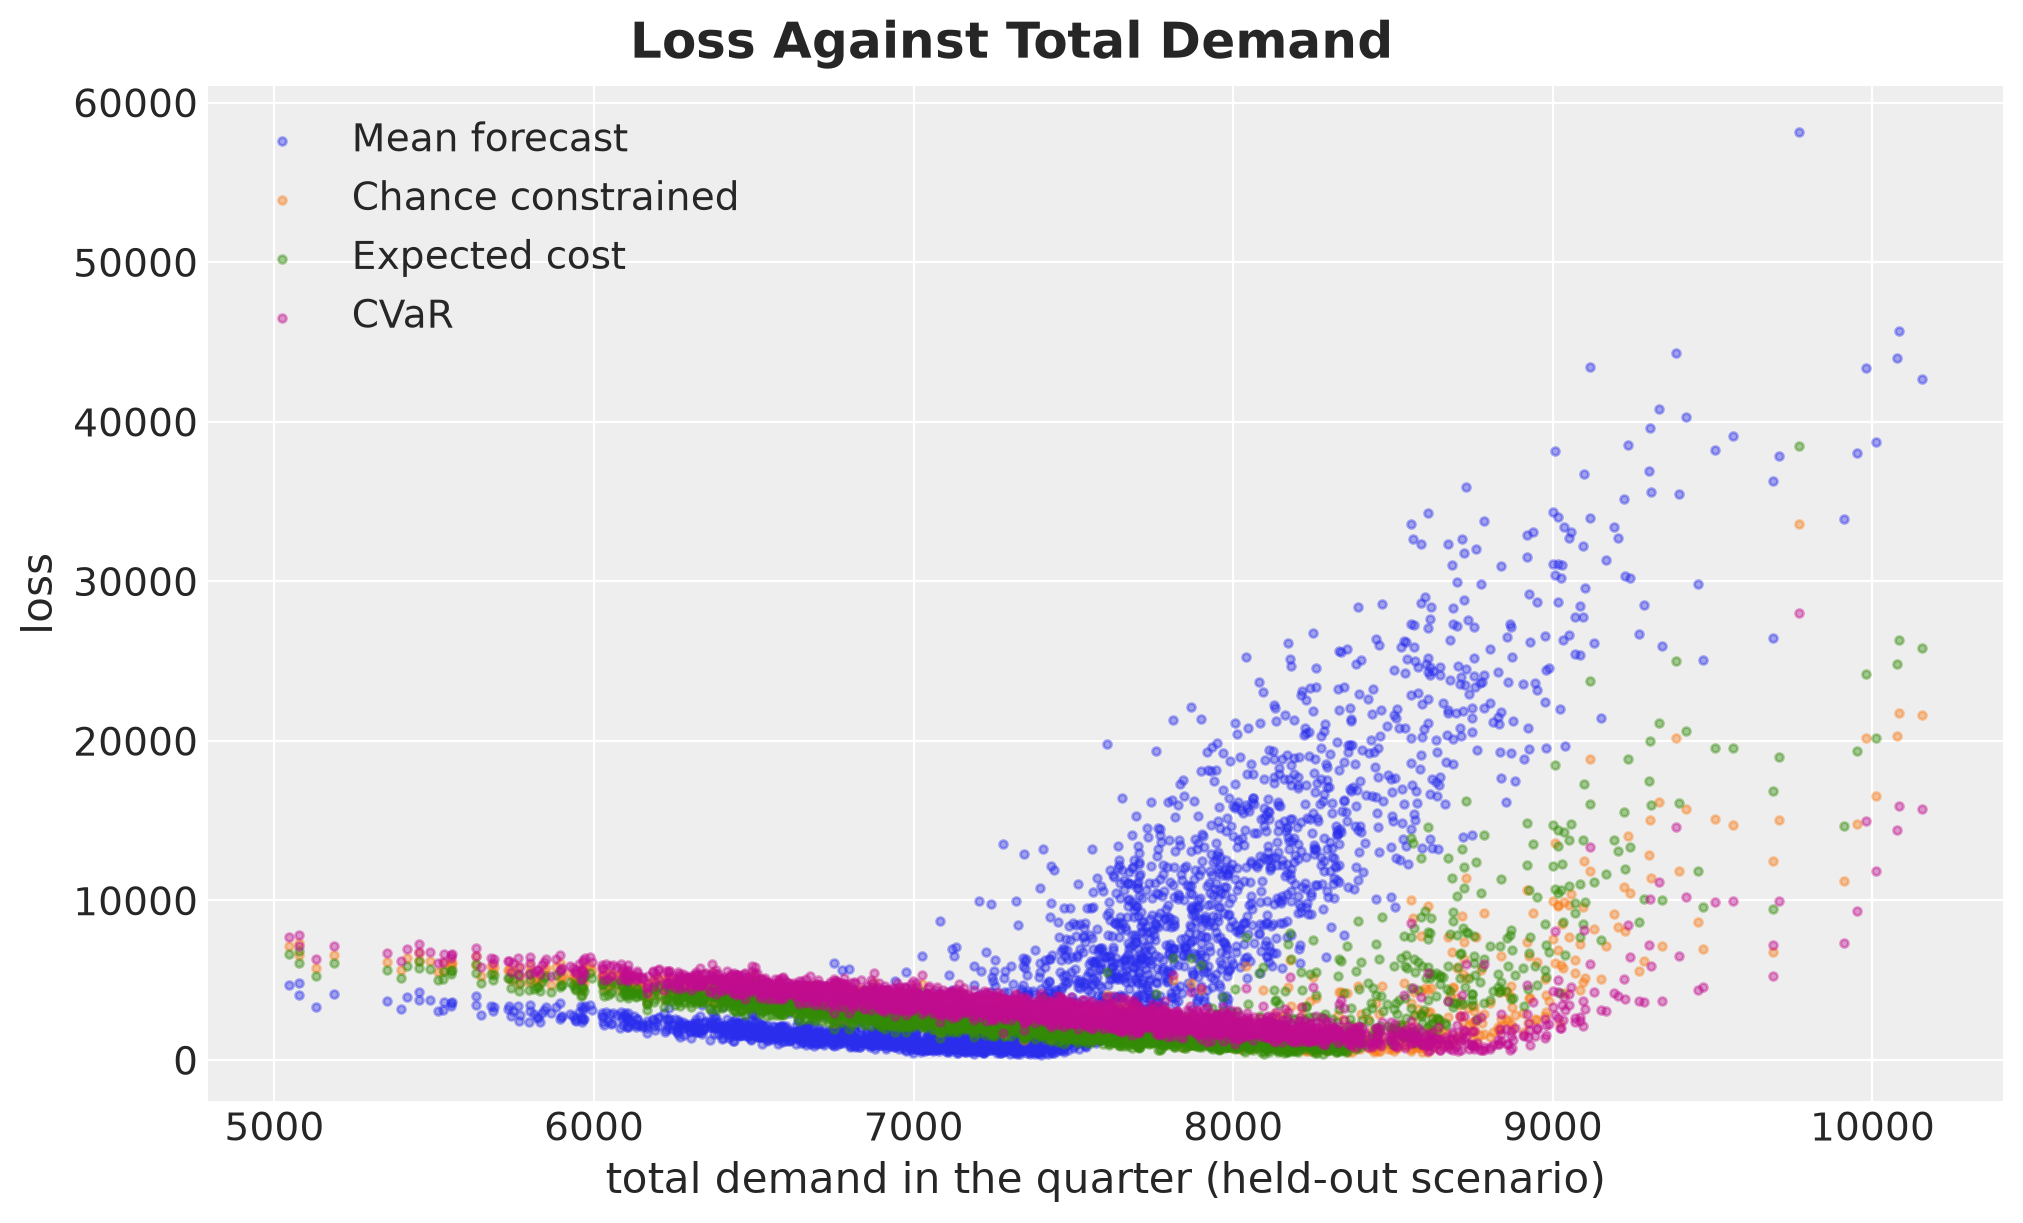

In [29]:
total_demand_eval = np.asarray(demand_eval.sum(axis=1))

fig, ax = plt.subplots()

for i, (name, (losses, _)) in enumerate(scores.items()):
    ax.scatter(
        total_demand_eval, np.asarray(losses), s=8, alpha=0.4, color=f"C{i}", label=name
    )

ax.legend(loc="upper left")
ax.set(xlabel="total demand in the quarter (held-out scenario)", ylabel="loss")
fig.suptitle("Loss Against Total Demand", fontsize=18, fontweight="bold");

Each plan traces a check mark: a shallow left arm where we pay holding costs and a steep right arm where we pay backorder costs. The buffered plans move the bottom of the check mark to the right, so fewer scenarios reach the steep arm. The mean forecast plan has its bottom at the mean demand, and half of the scenarios climb the steep arm. Next, let's look at the inventory paths under each plan.

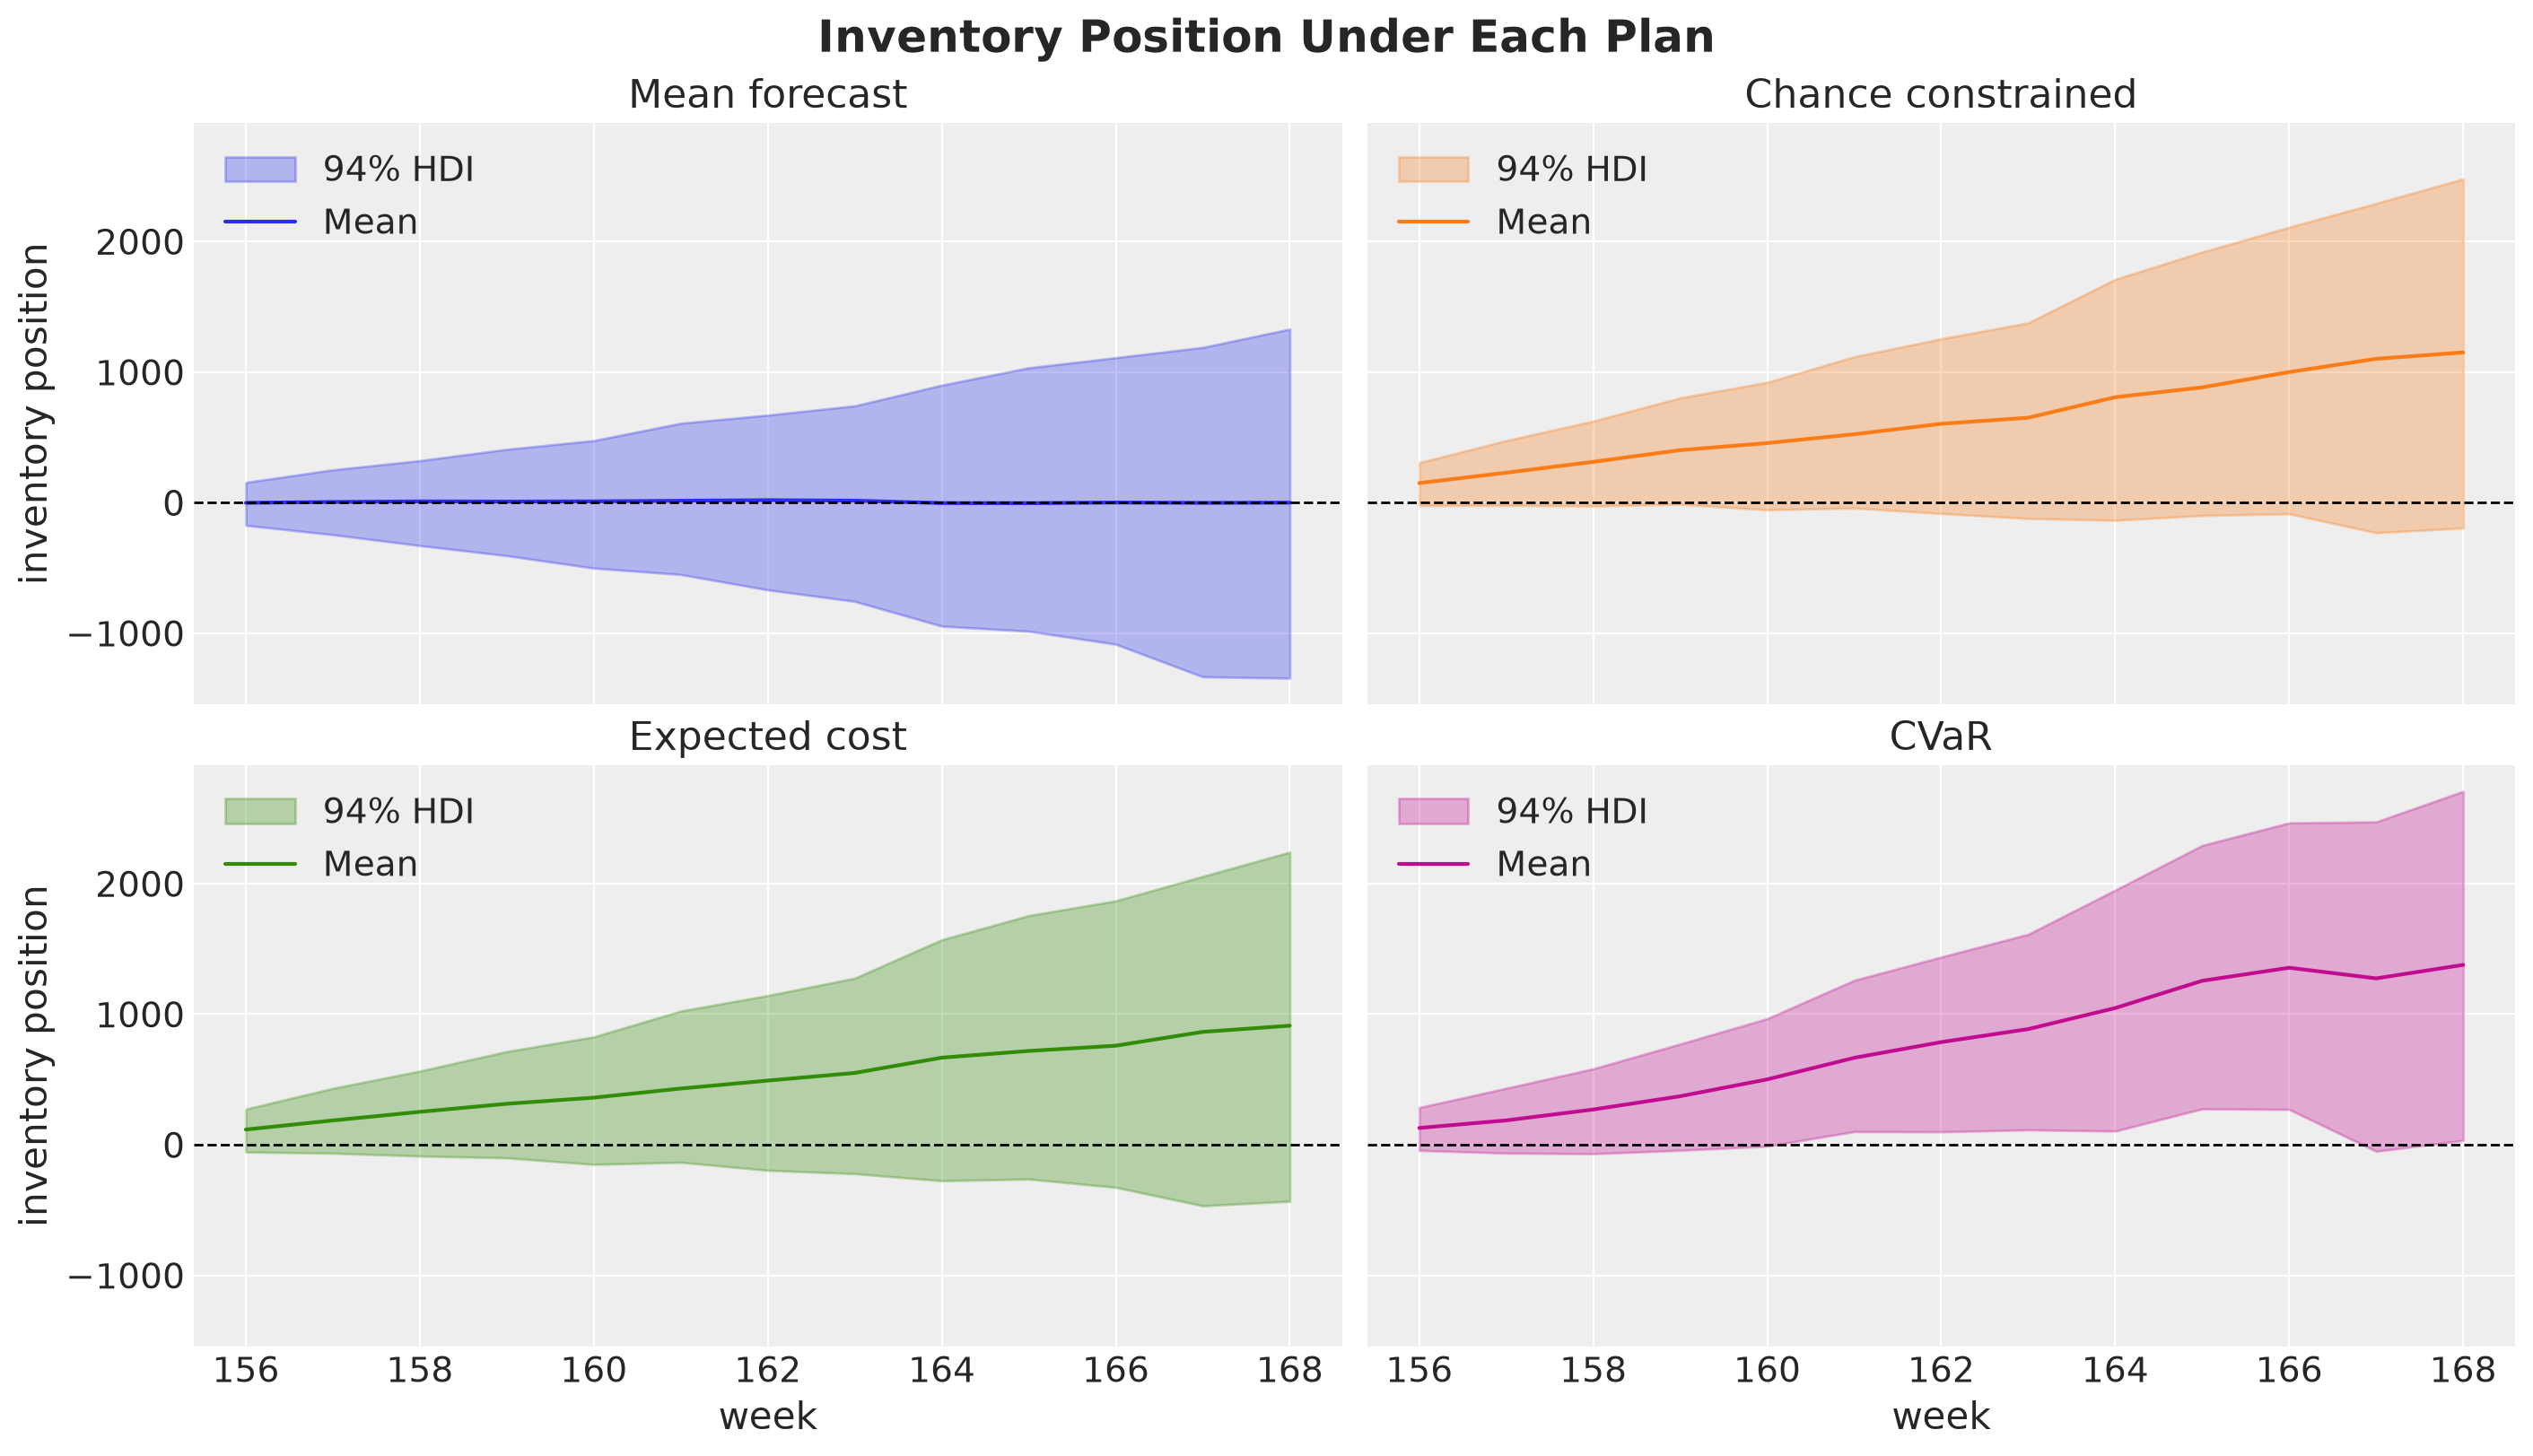

In [30]:
fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 8), sharex=True, sharey=True, layout="constrained"
)

for ax, (i, (name, (_, inventory))) in zip(
    axes.flat, enumerate(scores.items()), strict=True
):
    inventory_da = xr.DataArray(np.asarray(inventory), dims=("sample", "time"))
    inv_hdi = az.hdi(inventory_da, dim="sample")
    ax.fill_between(
        weeks_future,
        inv_hdi.sel(ci_bound="lower"),
        inv_hdi.sel(ci_bound="upper"),
        color=f"C{i}",
        alpha=0.3,
        label=f"{HDI_PROB:.0%} HDI",
    )
    ax.plot(weeks_future, inventory_da.mean("sample"), color=f"C{i}", label="Mean")
    ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
    ax.legend(loc="upper left")
    ax.set(title=name)

for ax in axes[-1]:
    ax.set(xlabel="week")

for ax in axes[:, 0]:
    ax.set(ylabel="inventory position")

fig.suptitle("Inventory Position Under Each Plan", fontsize=18, fontweight="bold");

The mean forecast plan keeps the expected inventory at zero, so half of its band sits below the dashed line. The other plans lift the whole band. The CVaR plan keeps the lower edge of the $94\%$ interval at about zero, the lower edge of the chance-constrained plan sits slightly below zero from the middle of the quarter on, and the expected cost plan accepts a lower edge further below.

Note that the mean position grows over the quarter under all three. The uncertainty of cumulative demand grows with the horizon, and a plan that cannot react has to hedge all of it up front. A plan with recourse, which re-forecasts and re-orders every week, would hedge one week at a time. We list this rolling horizon in the next steps.

## Pareto Frontier

The weight $\lambda$ has no natural scale. The useful object is the frontier it traces: for each $\lambda$ we solve the problem, score the plan out of sample, and plot the expected loss against the tail loss and against the stockout frequency. Because `solve` is a pure function, the whole sweep is one `jax.vmap` over the vector of weights, compiled once.

We also record which scenarios make up the worst $5\%$ under each plan. The share of them with a total demand below the median tells us whether the tail is made of high-demand or of low-demand quarters.

In [31]:
def low_demand_tail_share(
    losses: Float[Array, " scenarios"],
    demand: Float[Array, "scenarios horizon"],
    alpha: float,
) -> float:
    """Share of the worst alpha fraction of scenarios with below-median total demand."""
    _, worst = jax.lax.top_k(losses, round(alpha * losses.shape[0]))
    total_demand = demand.sum(axis=1)
    return float((total_demand[worst] < jnp.median(total_demand)).mean())

Let's run the sweep and score every plan on the held-out scenarios, with the tail composition measured on the optimization scenarios.

In [32]:
lambdas = jnp.array([0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 8.0])
solve_frontier = jax.jit(
    jax.vmap(solve, in_axes=(None, 0, None, None)),
    static_argnames=("problem", "n_steps"),
)
orders_frontier, _ = solve_frontier(demand_opt, lambdas, orders_mean, problem)

frontier = pl.DataFrame(
    [
        {
            "lambda": float(lam),
            **summarize(
                *simulate_scenarios(orders, demand_eval, problem), problem.alpha
            ),
            "low_demand_tail_share": low_demand_tail_share(
                simulate_scenarios(orders, demand_opt, problem)[0],
                demand_opt,
                problem.alpha,
            ),
        }
        for lam, orders in zip(lambdas, orders_frontier, strict=True)
    ]
)
print("share of low-demand scenarios in the worst 5%, by lambda:")
print(
    {
        f"{lam:g}": f"{share:.2f}"
        for lam, share in zip(
            frontier["lambda"], frontier["low_demand_tail_share"], strict=True
        )
    }
)

share of low-demand scenarios in the worst 5%, by lambda:
{'0': '0.10', '0.1': '0.48', '0.25': '0.62', '0.5': '0.74', '1': '0.82', '2': '0.86', '8': '0.90'}


Let's plot the frontier and mark the three plans on it. The mean forecast plan is far outside both panels, so we leave it out.

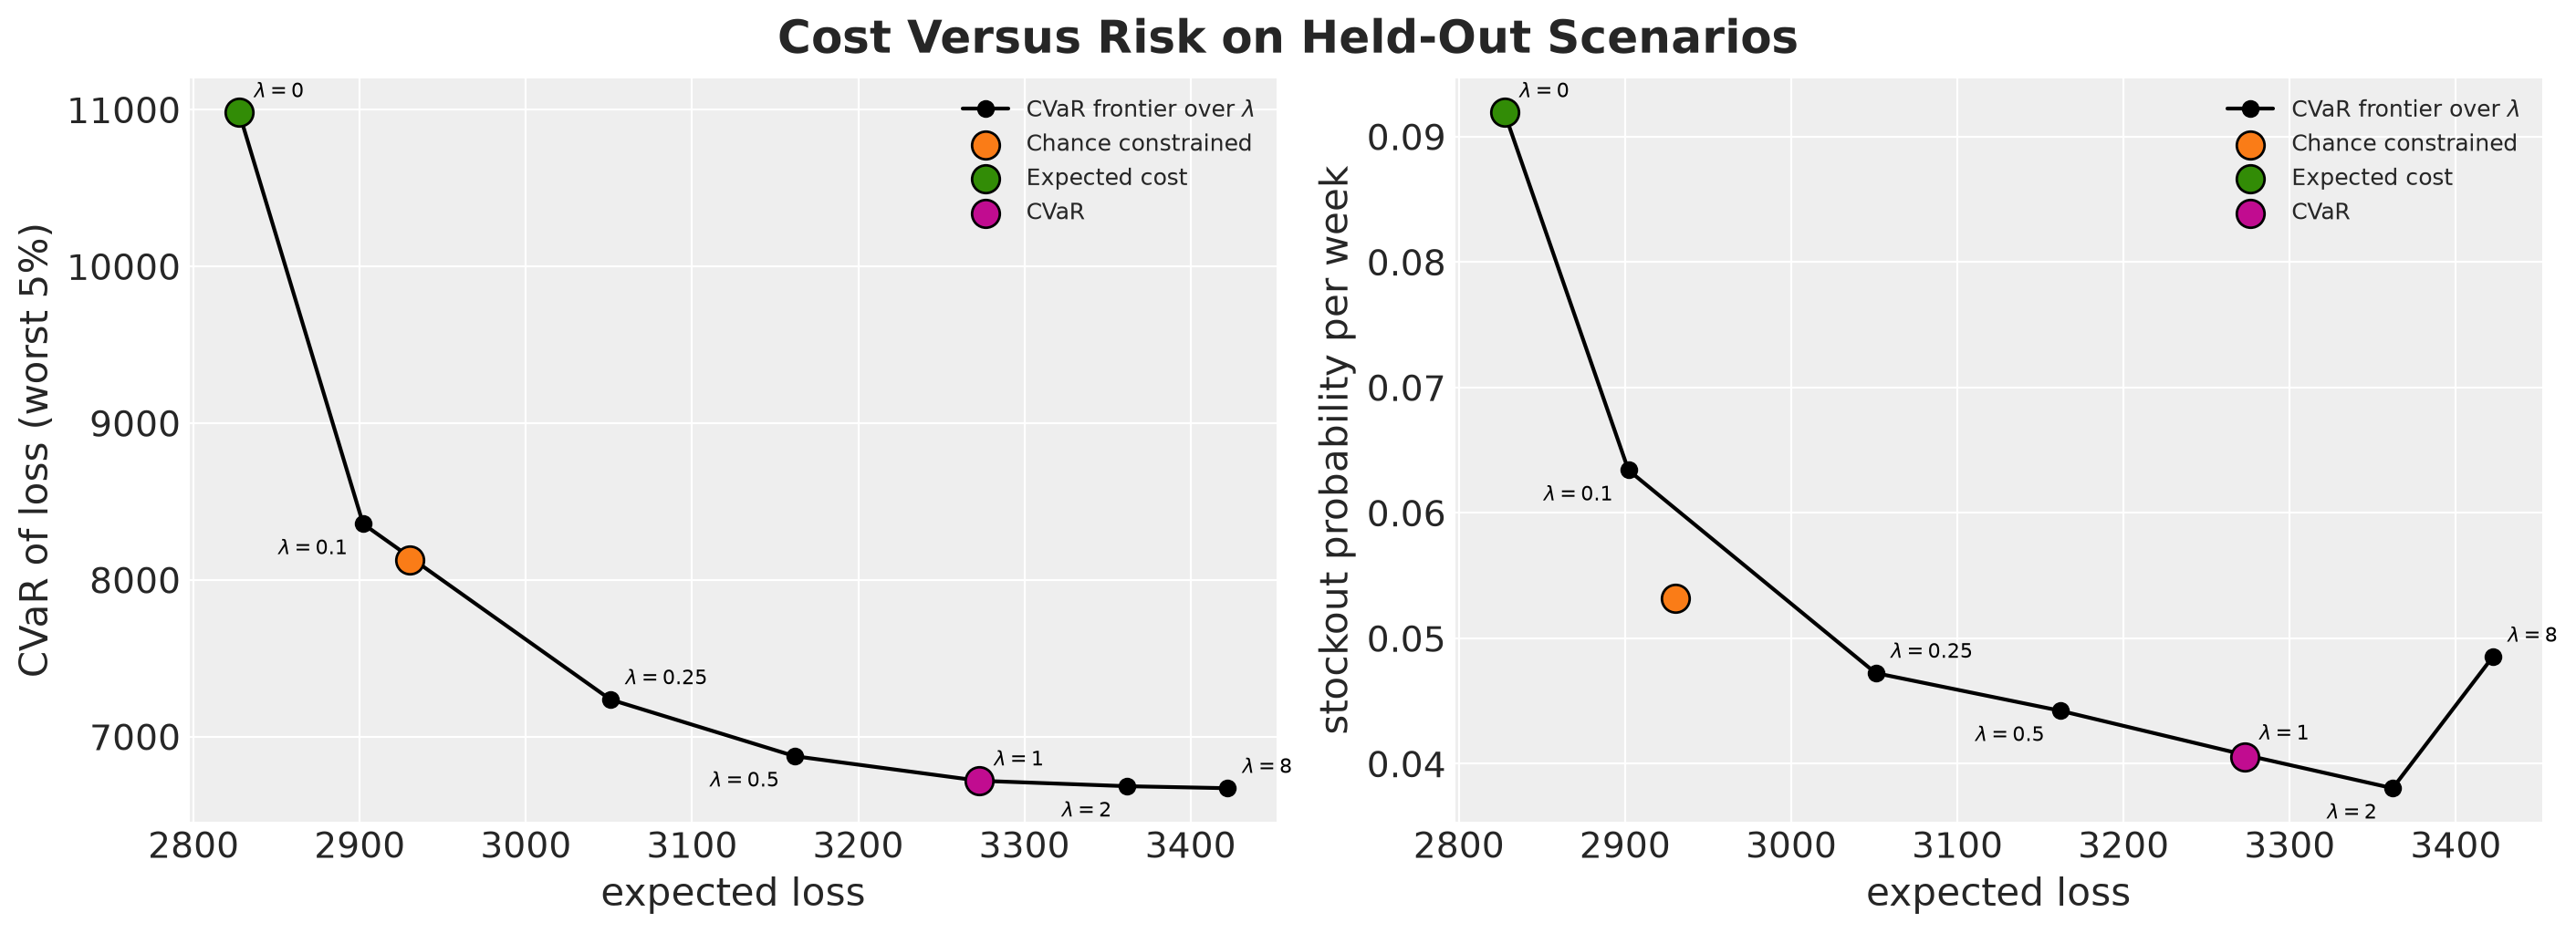

In [33]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 5), layout="constrained")

for ax, metric in zip(axes, ["cvar_loss", "stockout_prob_week"], strict=True):
    ax.plot(
        frontier["expected_loss"],
        frontier[metric],
        "o-",
        color="black",
        label=r"CVaR frontier over $\lambda$",
    )

    for j, (lam, x_val, y_val) in enumerate(
        zip(
            frontier["lambda"], frontier["expected_loss"], frontier[metric], strict=True
        )
    ):
        ax.annotate(
            rf"$\lambda={lam:g}$",
            (x_val, y_val),
            textcoords="offset points",
            xytext=(6, 6) if j % 2 == 0 else (-6, -12),
            ha="left" if j % 2 == 0 else "right",
            fontsize=8,
            color="black",
        )

    for i, row in enumerate(results.iter_rows(named=True)):
        if row["plan"] == "Mean forecast":
            continue

        ax.scatter(
            row["expected_loss"],
            row[metric],
            s=120,
            color=f"C{i}",
            edgecolor="black",
            zorder=5,
            label=row["plan"],
        )

    ax.set(xlabel="expected loss", ylabel=metric_labels[metric])
    ax.legend(loc="upper right", fontsize=9)

fig.suptitle("Cost Versus Risk on Held-Out Scenarios", fontsize=18, fontweight="bold");

The frontier is steep on the left and flat on the right. A small $\lambda$ removes a large part of the tail loss for a modest increase in expected loss: $\lambda = 0.1$ cuts the tail loss by a quarter for a $3\%$ increase in expected loss.

Beyond $\lambda \approx 1$ the tail loss stops improving while the expected loss keeps rising, and in the right panel the stockout frequency climbs back to about $5\%$ at $\lambda = 8$. The printed shares explain why. At $\lambda = 0$ the worst $5\%$ of the optimization scenarios are high-demand quarters, and only $10\%$ of them have a below-median total demand. At $\lambda = 8$ the plan carries so much stock that $90\%$ of the tail consists of low-demand quarters, which pay holding cost on the whole buffer. The CVaR term then shapes the plan around those quarters as well, and the scenarios in the middle run out more often.

This is the curve to put in front of the business: it prices one unit of tail loss, or one percentage point of stockout probability, in units of expected loss.

Here is an important observation. The chance-constrained plan sits on the frontier in the left panel and below it in the right panel. Both statements are consistent. CVaR trades expected loss against the tail average, and the chance constraint targets the stockout frequency. Each is efficient for the metric it targets, so the requirement decides which one to use.

## Convex Solver Cross Check

The projected gradient solver is convenient because it stays in JAX, but it is a first-order method on a non-smooth objective, so let's confirm that it reaches the optimum. Let $z$ be a loss threshold. The expected cost plus CVaR objective is a linear program once we use the Rockafellar and Uryasev representation

$$
\text{CVaR}_\alpha(L) = \min_{z} \left\{ z + \frac{1}{\alpha} \, \text{E}\left[(L - z)^{+}\right] \right\},
$$

where the minimizing $z$ is the value at risk. For $S$ equally weighted scenarios and an integer $k = \alpha S$, this minimum equals the mean of the $k$ largest losses, so the linear program minimizes the same objective as `solve`. With $L_s = L(x, D^{(s)})$, one auxiliary variable $u_s \geq (L_s - z)^{+}$ per scenario and the hinge terms of $L$ written with `cp.pos`, cvxpy hands the problem to HiGHS.

Building the expression tree over $1{,}000$ scenarios sometimes raises the numpy warning `invalid value encountered in reduce` inside the argument checks of cvxpy. It does not affect the solution, so we silence that one message around those lines.

In [34]:
def solve_lp(
    demand: Float[Array, "scenarios horizon"], lam: float, problem: Problem
) -> Float[Array, " horizon"]:
    """The same objective as `solve`, as a linear program."""
    demand = np.asarray(demand, dtype=np.float64)
    num_scenarios, horizon = demand.shape
    cumulative_demand = np.cumsum(demand, axis=1)
    orders = cp.Variable(horizon, nonneg=True)
    var = cp.Variable()
    excess = cp.Variable(num_scenarios, nonneg=True)

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="invalid value encountered in reduce",
            category=RuntimeWarning,
        )
        inventory = (
            problem.initial_inventory
            + cp.reshape(cp.cumsum(orders), (1, horizon), order="C")
            - cumulative_demand
        )
        losses = cp.sum(
            problem.holding_cost * cp.pos(inventory)
            + problem.backorder_cost * cp.pos(-inventory),
            axis=1,
        )
        cvar_term = var + cp.sum(excess) / (problem.alpha * num_scenarios)
        lp = cp.Problem(
            cp.Minimize(cp.sum(losses) / num_scenarios + lam * cvar_term),
            [excess >= losses - var],
        )

    lp.solve(solver=cp.HIGHS)
    return jnp.asarray(orders.value, dtype=jnp.float32)

We solve the two problems with cvxpy and overlay the order plans of both solvers. We evaluate `objective` at both solutions, so that the two values come from the same function, and we print them with their relative gap and the largest difference between the two order vectors. The panel titles repeat the last two.

Expected cost: objective JAX 2,737.3, LP 2,737.3, relative gap 8.9e-07, max order difference 3


CVaR: objective JAX 9,299.1, LP 9,298.0, relative gap 1.2e-04, max order difference 61


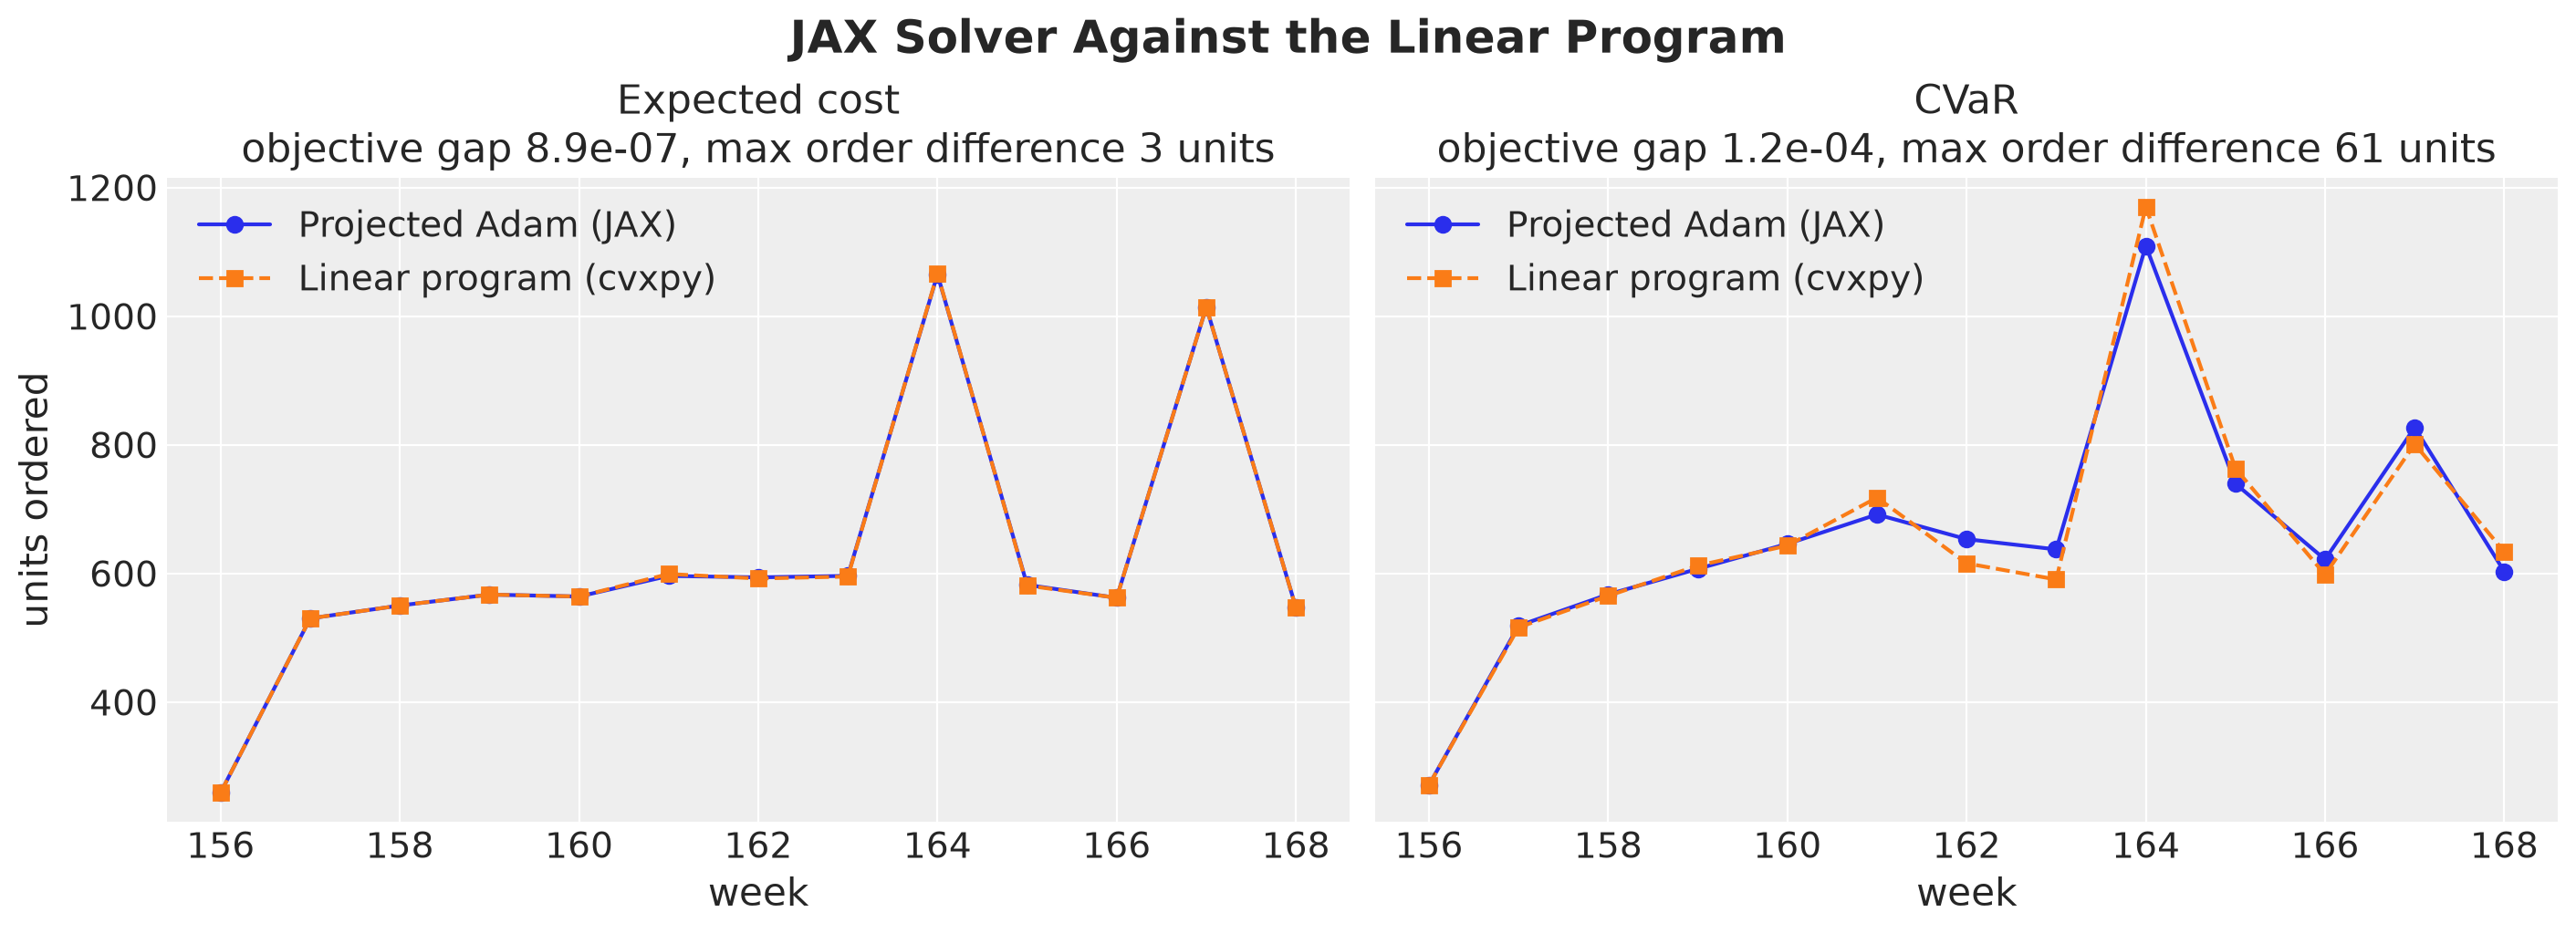

In [35]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 5), sharey=True, layout="constrained")

for ax, (name, lam, orders_jax) in zip(
    axes, [("Expected cost", 0.0, orders_saa), ("CVaR", 1.0, orders_cvar)], strict=True
):
    orders_lp = solve_lp(demand_opt, lam, problem)
    value_jax = float(objective(orders_jax, demand_opt, lam, problem))
    value_lp = float(objective(orders_lp, demand_opt, lam, problem))
    relative_gap = value_jax / value_lp - 1
    max_order_diff = float(jnp.abs(orders_jax - orders_lp).max())
    print(
        f"{name}: objective JAX {value_jax:,.1f}, LP {value_lp:,.1f}, "
        f"relative gap {relative_gap:.1e}, max order difference {max_order_diff:.0f}"
    )
    ax.plot(
        weeks_future,
        np.asarray(orders_jax),
        "o-",
        color="C0",
        label="Projected Adam (JAX)",
    )
    ax.plot(
        weeks_future,
        np.asarray(orders_lp),
        "s--",
        color="C1",
        label="Linear program (cvxpy)",
    )
    ax.legend(loc="upper left")
    ax.set(
        xlabel="week",
        title=f"{name}\nobjective gap {relative_gap:.1e}, "
        f"max order difference {max_order_diff:.0f} units",
    )

axes[0].set(ylabel="units ordered")
fig.suptitle("JAX Solver Against the Linear Program", fontsize=18, fontweight="bold");

The two solvers agree! The relative objective gaps are $9 \times 10^{-7}$ for the expected cost plan and $1 \times 10^{-4}$ for the CVaR plan. The order quantities differ by up to $3$ units in the first case and up to $61$ units in the second, on orders of several hundred. This is the flat region of a piecewise-linear objective near its optimum: shifting units between neighboring weeks barely moves the objective, and the CVaR objective is flatter because only $50$ scenarios enter the tail term. We use the JAX solver to vectorize over weights or over products, and the LP when the problem gains integer decisions or coupling constraints.

Finally, as a single sanity check, we score the four plans on the one true future path we held out at the start. One path is noisy, so we read this as a consistency check. The bar labels count the weeks in backlog.

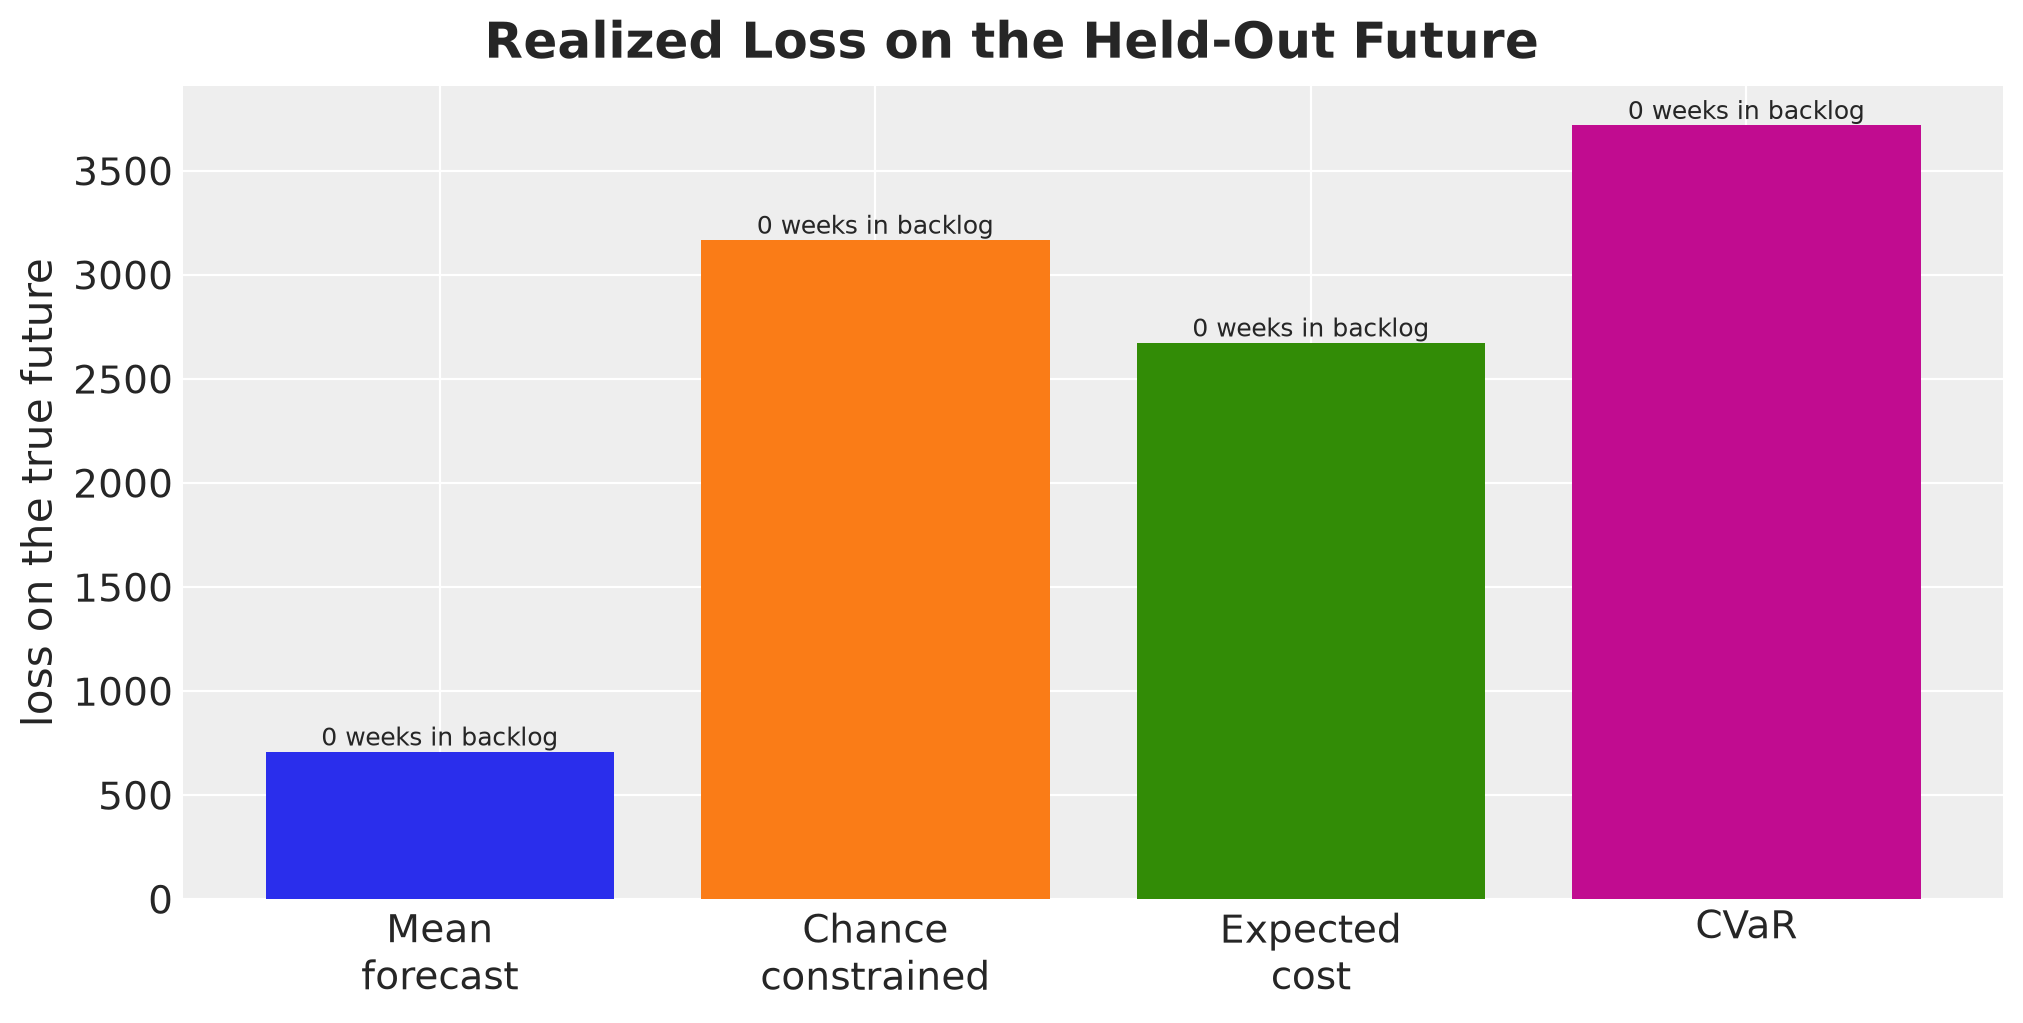

In [36]:
realized_paths = {
    name: simulate(orders, demand_future_true, problem)
    for name, orders in plans.items()
}
realized = pl.DataFrame(
    [
        {
            "plan": name,
            "realized_loss": float(loss),
            "weeks_in_backlog": int((inventory < 0).sum()),
        }
        for name, (loss, inventory) in realized_paths.items()
    ]
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(plan_labels, realized["realized_loss"].to_numpy(), color=plan_colors)
ax.bar_label(
    bars,
    labels=[f"{weeks} weeks in backlog" for weeks in realized["weeks_in_backlog"]],
    fontsize=9,
)
ax.set(ylabel="loss on the true future")
fig.suptitle("Realized Loss on the Held-Out Future", fontsize=18, fontweight="bold");

The true path ran at or below the forecast mean in most weeks, so no plan ran out of stock, and the mean forecast plan had the lowest realized loss because it held the least stock. On the $3{,}000$ held-out scenarios the same plan was the most expensive by a factor of two, so one path does not rank the plans.

## Conclusion

### Key Findings

- **The forecast is the scenario matrix.** All four plans are built from the same $1{,}000$ joint posterior predictive scenarios and scored on the same $3{,}000$ held-out ones. The only modeling choice at the decision step is the functional of the loss distribution, and that choice moved the expected loss by a factor of more than two across plans.
- **A point forecast hides the cost.** The mean forecast plan costs nothing on the mean path and the most on the distribution. The loss is non-linear in demand, so the expectation of the loss differs from the loss at the expected demand.
- **The risk-neutral plan is the critical fractile.** Minimizing expected cost gives a weekly stockout probability near $1 - p / (p + h)$. A service level target needs a chance constraint. A CVaR term prices the tail loss and does not control the frequency.
- **Each functional is efficient for its own metric.** The chance-constrained plan sits on the CVaR frontier when we measure tail loss and beats it when we measure stockout frequency, because frequency is what it targets. A large CVaR weight even raises the stockout frequency, because the tail fills with low-demand quarters that pay holding cost. Pick the functional that matches the requirement the business states.
- **Known covariates sharpen the scenarios.** The price path is set by the retailer, so the forecast knows the promotion weeks in the horizon and every plan raises its order for those weeks.
- **JAX covers the whole pipeline.** The loss is a `lax.scan`, the scenarios are a `vmap`, the tail is a `lax.top_k`, the solver is a `lax.scan` under `jit`, and the frontier is a `vmap` over the weight. The projected gradient solver matched the LP optimum to about $10^{-4}$.

### Model Limitations

- **No recourse.** All orders are fixed at the start of the quarter. A rolling horizon that re-forecasts and re-solves each week, and commits only the next order, is the practical version of this problem.
- **Same model in and out of sample.** We evaluate the plans on scenarios from the same model that produced the optimization set, so model misspecification does not show up in the held-out scores. A backtest on real data would expose it.
- **Linear backorders.** Backorders carry at a linear cost. Lost sales, lead times, order minimums and fixed ordering costs change the simulator, and integer order quantities change the solver.
- **In-sample optimism.** The sample average approximation with $1{,}000$ scenarios is optimistic in sample. We scored out of sample for that reason.

### Recommendations

1. **Report the whole frontier.** The weight $\lambda$ is a business decision, and the frontier shows what one percentage point of reliability costs.
2. **Keep the scenarios joint.** Marginal quantiles per week break every constraint that couples weeks, products or hierarchy levels.
3. **Validate the first-order solver once.** Check it against a convex solver once per problem class, then use the JAX version for the sweeps.

## Next Steps

1. **Rolling horizon.** Wrap the solve in `numpyro_forecast.backtest` so that each window re-forecasts, re-solves and commits one order.
2. **Lead time and lost sales.** Add a pipeline of in-transit orders to the scan carry and replace the backlog by a lost-sales branch. Only the simulator changes.
3. **Many products.** Fit a hierarchical forecast and `vmap` the solver over the product axis, with a shared budget constraint as a second projection step.
4. **Distributionally robust variant.** Reweight the scenarios adversarially within a divergence ball to see how much of the frontier survives when the forecast tails are not trusted.

## References

- Rockafellar, R. T. and Uryasev, S. (2000). [Optimization of conditional value-at-risk](https://www.risk.net/journal-risk/2161159/optimization-conditional-value-risk). *Journal of Risk*, 2(3), 21-41.
- Shapiro, A., Dentcheva, D. and Ruszczyński, A. (2021). [Lectures on Stochastic Programming: Modeling and Theory](https://doi.org/10.1137/1.9781611976595), third edition. SIAM.
- Birge, J. R. and Louveaux, F. (2011). [Introduction to Stochastic Programming](https://link.springer.com/book/10.1007/978-1-4614-0237-4), second edition. Springer.
- FICO Xpress Community. [Stochastic Energy Planning: PyMC + FICO Xpress Optimization](https://github.com/fico-xpress/xpress-community/tree/main/StochasticEnergyPlanning).
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- Diamond, S. and Boyd, S. (2016). [CVXPY: A Python-embedded modeling language for convex optimization](https://jmlr.org/papers/v17/15-408.html). *Journal of Machine Learning Research*, 17(83), 1-5.
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).